<a href="https://colab.research.google.com/github/mdrehanmustufa/future-crude-oil-prediction/blob/main/Future_Crude_oil_price_pridiction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WTI next-trading-day forecasting: EDA and model evaluation
**Reproducible Colab notebook.** Forecast cutoff: after market close on day *t*, predict the next observed trading session. No random split, no NaN filling, no outlier deletion. All feature columns are screened against target/date/eligibility leakage.

**Important:** `ELIGIBLE_core` and `ELIGIBLE_extended` define row availability, not proof of point-in-time correctness. Weekly release timestamps and several source-alignment assumptions remain unverified. This notebook does not claim the dataset is leakage-free.

## 1. Install dependencies and import libraries

In [1]:
%pip -q install statsmodels xgboost lightgbm shap scikit-learn matplotlib seaborn scipy
import os, sys, json, warnings, zipfile, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, confusion_matrix,
    classification_report)
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.inspection import permutation_importance
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
import statsmodels.api as sm
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")
OUT = Path("/content/outputs")
OUT.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| platform:", platform.platform())

Python: 3.13.16 | pandas: 2.2.3 | platform: Linux-6.6.159+-x86_64-with-glibc2.39


## 2. Upload the supervised dataset

In [2]:
DATA_PATH = None
try:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        DATA_PATH = next(iter(uploaded.keys()))
except Exception:
    pass
if not DATA_PATH or not Path(DATA_PATH).exists():
    # Fallback: mount Google Drive and set the path below.
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception:
        pass
    DATA_PATH = '/content/Final_Dataset_AI.csv'
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}. Upload it or update DATA_PATH.")
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print("Loaded:", DATA_PATH, "| shape:", df.shape)

Saving Final_Dataset_AI.csv to Final_Dataset_AI (1).csv
Loaded: Final_Dataset_AI (1).csv | shape: (3016, 37)


## 3. Load audit: schema, duplicates, sort order, and date gaps

In [3]:
expected_rows = 3016
print("Shape:", df.shape)
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "nunique": df.nunique(dropna=True)}))
print("Duplicate full rows:", df.duplicated().sum())
print("Duplicate dates:", df["Date"].duplicated().sum())
print("Already sorted:", df["Date"].is_monotonic_increasing)
df = df.sort_values("Date").reset_index(drop=True)
print("Date range:", df.Date.min(), "to", df.Date.max())
calendar = pd.date_range(df.Date.min(), df.Date.max(), freq="D")
missing_calendar_dates = calendar.difference(pd.DatetimeIndex(df.Date))
print("Calendar days without rows:", len(missing_calendar_dates), "(weekends/holidays expected; not automatically errors)")
print("Non-increasing date pairs:", int((df.Date.diff().dropna() <= pd.Timedelta(0)).sum()))
assert df["Date"].notna().all() and not df["Date"].duplicated().any(), "Date key must be unique and non-null."
assert df["Date"].is_monotonic_increasing

Shape: (3016, 37)


,dtype,missing,nunique
Date,datetime64[ns],0,3016
WTI_Open,float64,0,2368
WTI_High,float64,0,2355
WTI_Low,float64,0,2383
WTI_Close,float64,0,2404
WTI_Volume,float64,0,3000
WTI_ret_1d,float64,4,2995
WTI_ret_lag1,float64,5,2994
WTI_ret_lag2,float64,6,2993
WTI_ret_lag4,float64,8,2991


Duplicate full rows: 0
Duplicate dates: 0
Already sorted: True
Date range: 2014-10-27 00:00:00 to 2026-10-23 00:00:00
Calendar days without rows: 1364 (weekends/holidays expected; not automatically errors)
Non-increasing date pairs: 0


**Conclusion:** Missing calendar dates are expected in a trading-day series. Duplicate dates or unsorted rows are not; the cell asserts date-key integrity after sorting.

## 4. Missingness by column and year

,missing_count,missing_pct
CMD_wheat_lag1,122,4.045093
CMD_ttf_lag1,122,4.045093
CMD_urals_lag1,122,4.045093
CMD_brent_lag1,122,4.045093
CMD_espo_lag1,122,4.045093
CMD_urea_lag1,122,4.045093
EIA_world_prod_lag3m,46,1.525199
DXY_ret_1d,15,0.497347
WTI_vol_20d,15,0.497347
DXY_Close,13,0.431034


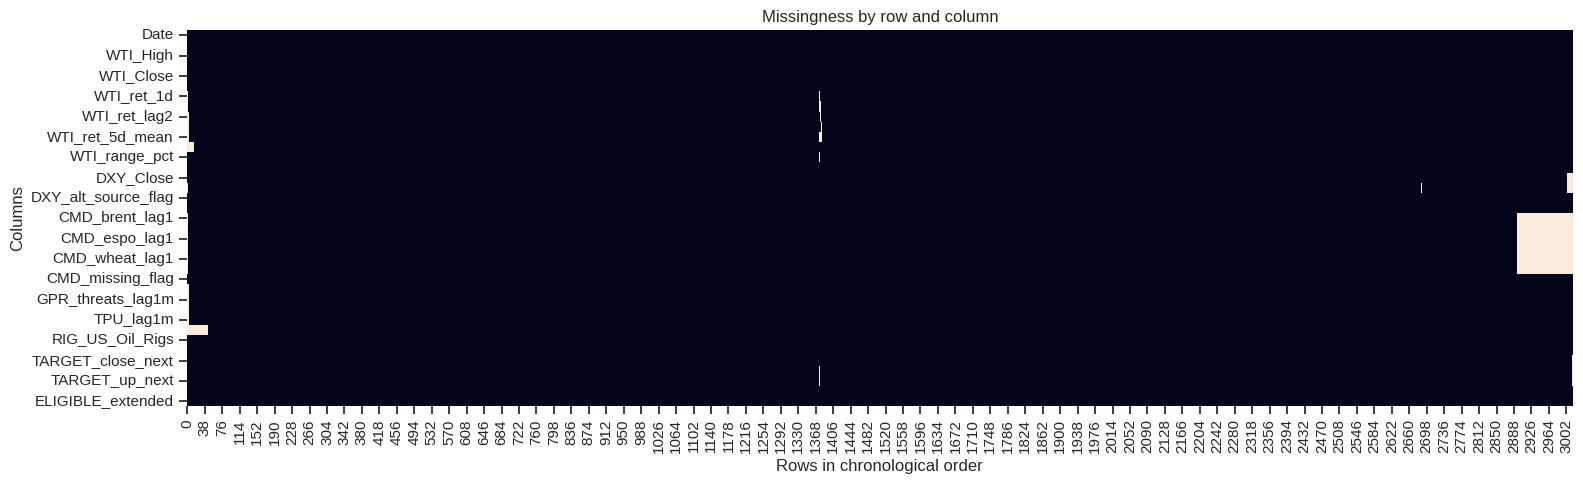

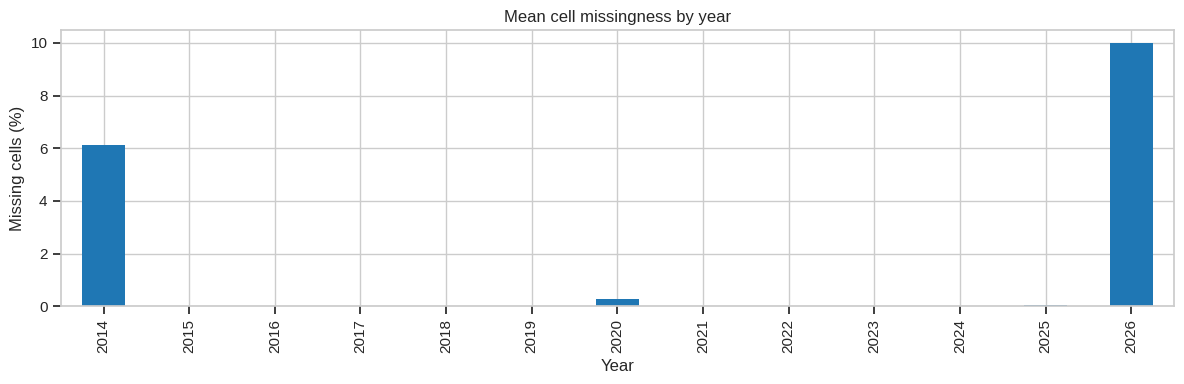

Flag checks:
CMD_missing_flag flagged rows: 122 | missing in associated fields: 122
DXY_missing_flag flagged rows: 13 | missing in associated fields: 15


In [4]:
missing = df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame()
missing["missing_pct"] = 100 * missing.missing_count / len(df)
display(missing)
fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(df.isna().T, cbar=False, ax=ax)
ax.set(title="Missingness by row and column", xlabel="Rows in chronological order", ylabel="Columns")
fig.tight_layout(); fig.savefig(OUT/"04_missingness_heatmap.png", dpi=160); plt.show()
year_missing = df.assign(year=df.Date.dt.year).groupby("year").apply(lambda x: x.drop(columns="year").isna().mean().mean()*100)
fig, ax = plt.subplots(figsize=(12, 4)); year_missing.plot(kind="bar", ax=ax)
ax.set(title="Mean cell missingness by year", ylabel="Missing cells (%)", xlabel="Year")
fig.tight_layout(); fig.savefig(OUT/"04_missingness_by_year.png", dpi=160); plt.show()
print("Flag checks:")
for flag, cols in {"CMD_missing_flag":[c for c in df if c.startswith("CMD_") and c.endswith("_lag1")],
                   "DXY_missing_flag":["DXY_Close","DXY_ret_1d"]}.items():
    if flag in df:
        print(flag, "flagged rows:", int((df[flag] == 1).sum()), "| missing in associated fields:", int(df[cols].isna().any(axis=1).sum()))

**Conclusion:** Do not fill any NaNs in this notebook. Initial technical-feature NaNs are expected from lookback windows; monthly and weekly series have their own coverage/release-timing caveats. The commodity block is documented as unavailable/suspect after 2026-04-30. Compare these patterns with `CMD_missing_flag`, `DXY_missing_flag`, and eligibility flags; a flag does not itself validate source timing.

## 5. WTI price history, negative-price episode, and 2022 spike

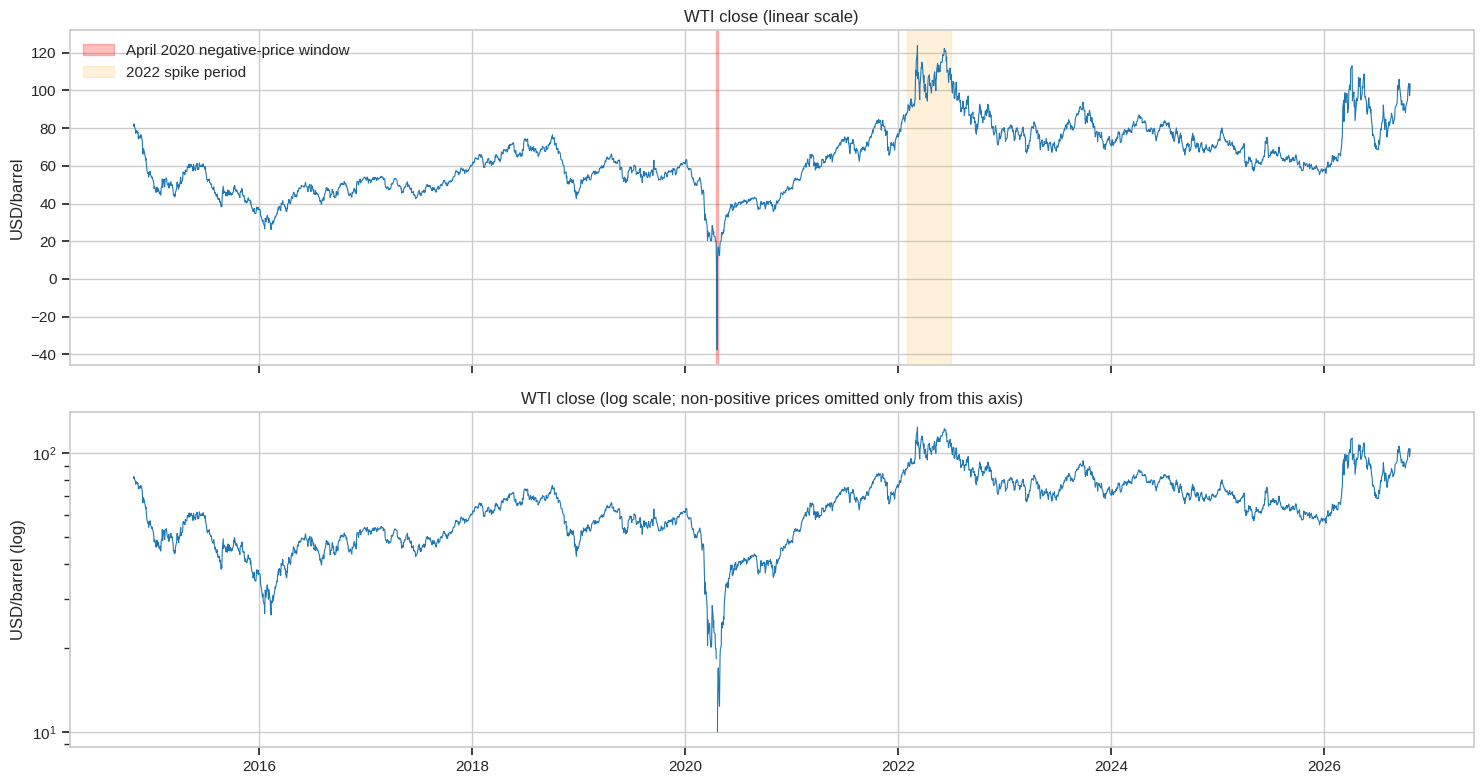

Minimum close: -37.63 on 2020-04-20 00:00:00
Negative or zero closes: 1


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
axes[0].plot(df.Date, df.WTI_Close, lw=.8)
axes[0].axvspan(pd.Timestamp("2020-04-15"), pd.Timestamp("2020-04-24"), alpha=.25, color="red", label="April 2020 negative-price window")
axes[0].axvspan(pd.Timestamp("2022-02-01"), pd.Timestamp("2022-06-30"), alpha=.15, color="orange", label="2022 spike period")
axes[0].set(title="WTI close (linear scale)", ylabel="USD/barrel"); axes[0].legend()
positive = df.WTI_Close.where(df.WTI_Close > 0)
axes[1].plot(df.Date, positive, lw=.8)
axes[1].set_yscale("log"); axes[1].set(title="WTI close (log scale; non-positive prices omitted only from this axis)", ylabel="USD/barrel (log)")
fig.tight_layout(); fig.savefig(OUT/"05_wti_price_history.png", dpi=160); plt.show()
print("Minimum close:", df.WTI_Close.min(), "on", df.loc[df.WTI_Close.idxmin(),"Date"])
print("Negative or zero closes:", int((df.WTI_Close <= 0).sum()))

**Conclusion:** The April 2020 negative-price episode is genuine and retained. Log scale cannot display non-positive prices, so those observations are omitted from the log panel only, not from the dataset.

## 6. Return distribution and normality diagnostics

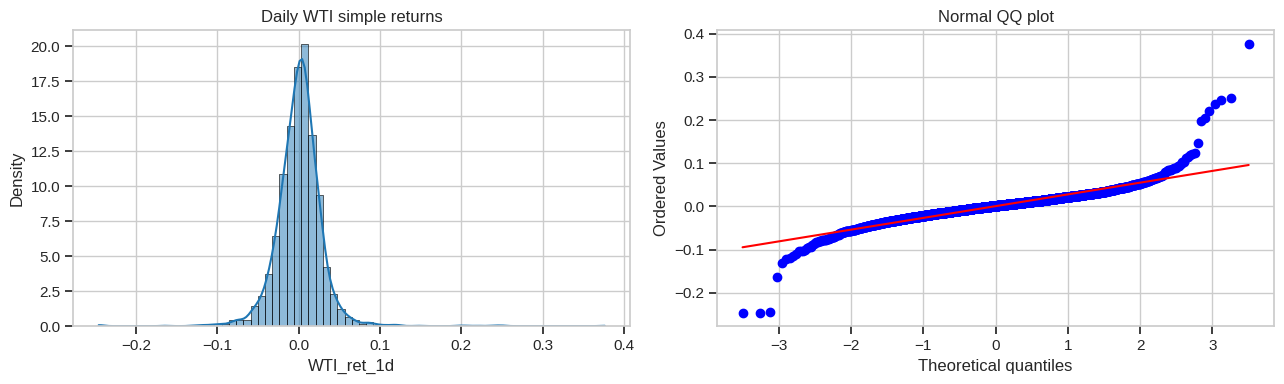

,n,mean,std,skew,excess_kurtosis,Jarque_Bera,JB_p_value
0,3012,0.000736,0.029372,0.900947,21.7868,59769.093685,0.0


Jarque-Bera rejects normality at 5%: True


In [6]:
r = pd.to_numeric(df["WTI_ret_1d"], errors="coerce").dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(r, bins=70, stat="density", kde=True, ax=axes[0]); axes[0].set(title="Daily WTI simple returns")
stats.probplot(r, dist="norm", plot=axes[1]); axes[1].set_title("Normal QQ plot")
fig.tight_layout(); fig.savefig(OUT/"06_return_distribution.png", dpi=160); plt.show()
jb_stat, jb_p, skewness, kurtosis = jarque_bera(r)
display(pd.DataFrame([{"n":len(r),"mean":r.mean(),"std":r.std(),"skew":r.skew(),"excess_kurtosis":r.kurtosis(),
                       "Jarque_Bera":jb_stat,"JB_p_value":jb_p}]))
print("Jarque-Bera rejects normality at 5%:", jb_p < .05)

**Conclusion:** Heavy tails and skew are common in commodity returns. The Jarque-Bera test is descriptive and does not establish a forecasting strategy.

## 7. Stationarity: ADF and KPSS on price versus returns

In [7]:
def stationarity_row(series, name):
    x = pd.Series(series).replace([np.inf, -np.inf], np.nan).dropna()
    out = {"series":name, "n":len(x)}
    try:
        out["ADF_stat"] = adfuller(x, autolag="AIC")[0]; out["ADF_p"] = adfuller(x, autolag="AIC")[1]
    except Exception: out["ADF_stat"], out["ADF_p"] = np.nan, np.nan
    try:
        k = kpss(x, regression="c", nlags="auto"); out["KPSS_stat"], out["KPSS_p"] = k[0], k[1]
    except Exception: out["KPSS_stat"], out["KPSS_p"] = np.nan, np.nan
    return out
stationarity = pd.DataFrame([stationarity_row(df.WTI_Close,"WTI_Close_level"), stationarity_row(df.WTI_ret_1d,"WTI_return")])
display(stationarity)
print("ADF null: unit root. KPSS null: level stationarity. Interpret jointly, with caution around structural breaks.")

,series,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p
0,WTI_Close_level,3016,-2.250248,1.885162e-01,4.039731,0.01
1,WTI_return,3012,-10.246245,4.609605e-18,0.117015,0.10


ADF null: unit root. KPSS null: level stationarity. Interpret jointly, with caution around structural breaks.


**Conclusion:** Price levels are typically less stationary than returns. If results disagree, treat tests as inconclusive; structural breaks and the 2020 episode can affect both tests. Modeling returns is the primary path here.

## 8. ACF/PACF, squared returns, and Ljung-Box

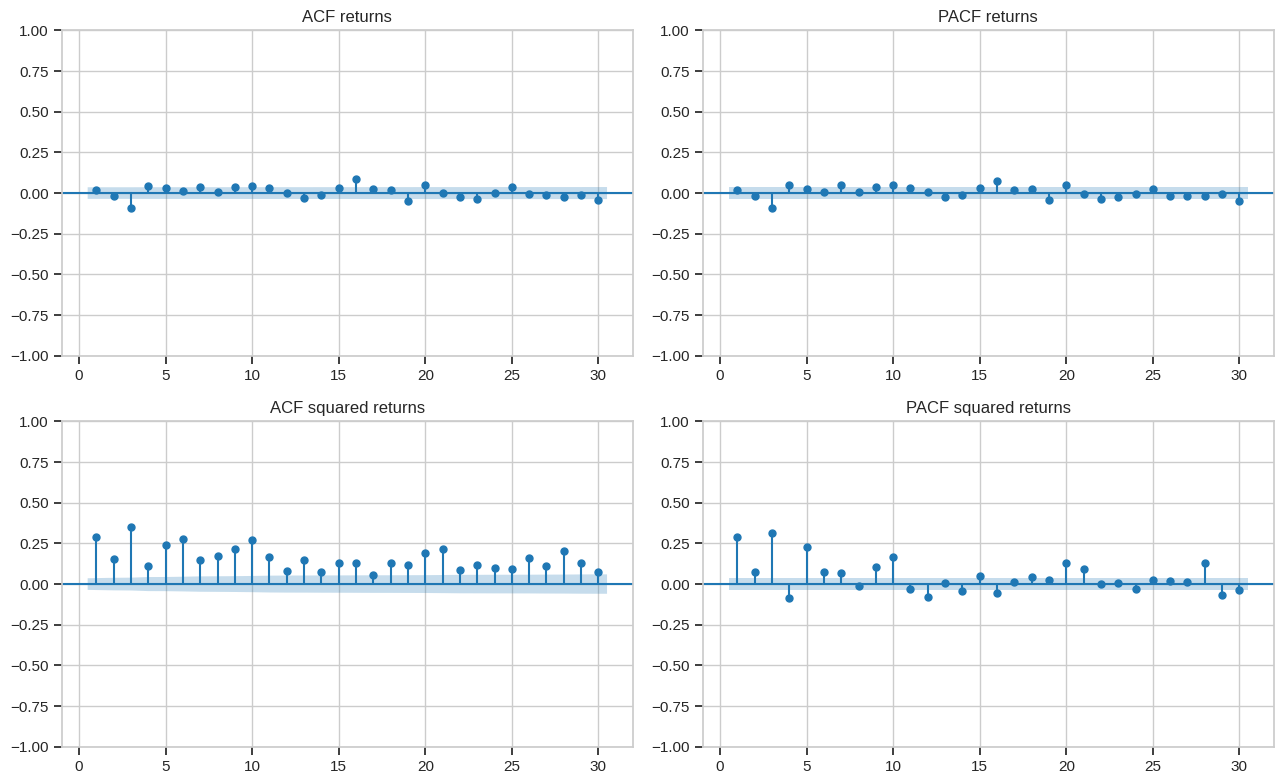

,lb_stat,lb_pvalue
lag,,
5,35.600041,1.141836e-06
10,50.658727,2.018770e-07
20,101.923277,5.693283e-13


,lb_stat,lb_pvalue
squared_return_lag,,
5,905.095731,2.100190e-193
10,1660.277281,0.000000e+00
20,2160.337477,0.000000e+00


In [8]:
r_full = df.WTI_ret_1d.replace([np.inf,-np.inf], np.nan).dropna()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_acf(r_full, lags=30, ax=axes[0,0], zero=False); axes[0,0].set_title("ACF returns")
plot_pacf(r_full, lags=30, ax=axes[0,1], zero=False, method="ywm"); axes[0,1].set_title("PACF returns")
plot_acf(r_full**2, lags=30, ax=axes[1,0], zero=False); axes[1,0].set_title("ACF squared returns")
plot_pacf(r_full**2, lags=30, ax=axes[1,1], zero=False, method="ywm"); axes[1,1].set_title("PACF squared returns")
fig.tight_layout(); fig.savefig(OUT/"08_acf_pacf.png", dpi=160); plt.show()
display(acorr_ljungbox(r_full, lags=[5,10,20], return_df=True).rename_axis("lag"))
display(acorr_ljungbox(r_full**2, lags=[5,10,20], return_df=True).rename_axis("squared_return_lag"))

**Conclusion:** Significant squared-return autocorrelation is consistent with volatility clustering, not necessarily predictable return direction.

## 9. Rolling volatility and WTI-DXY rolling correlation

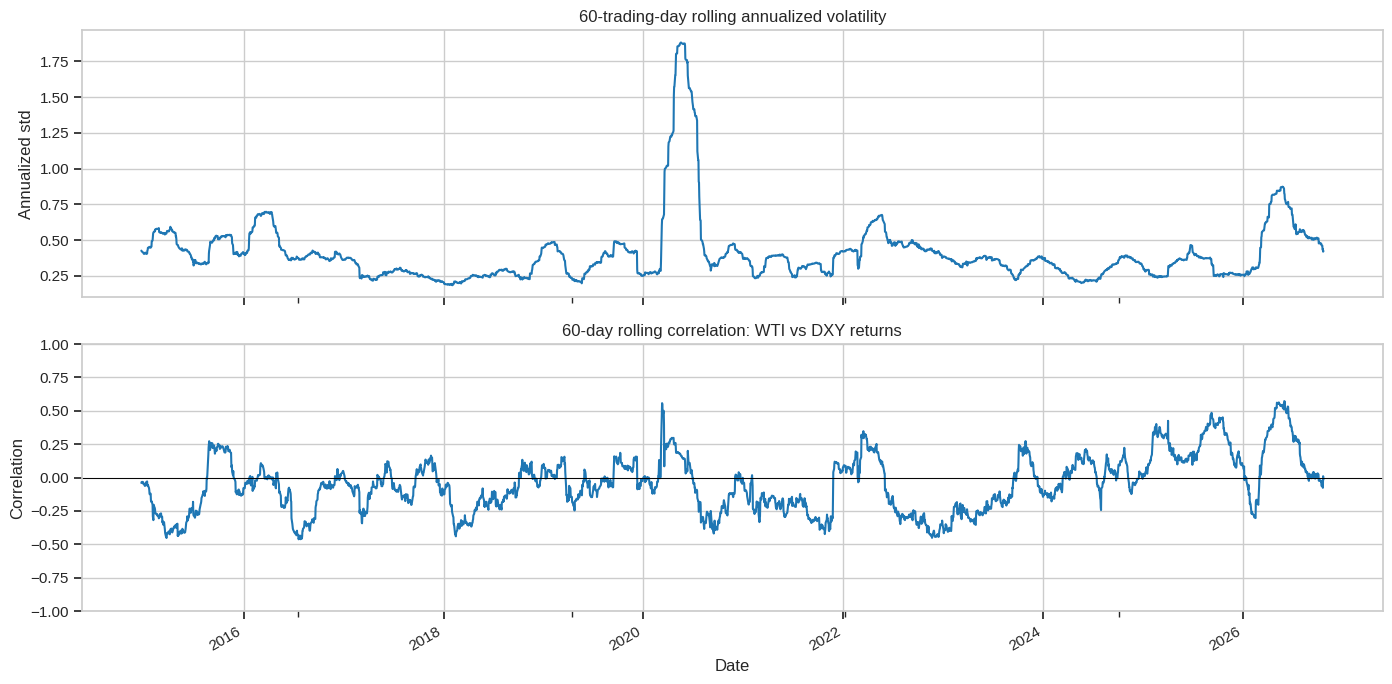

In [9]:
tmp = df.set_index("Date")
roll_vol = tmp.WTI_ret_1d.rolling(60, min_periods=40).std() * np.sqrt(252)
roll_corr = tmp.WTI_ret_1d.rolling(60, min_periods=40).corr(tmp.DXY_ret_1d)
fig, axes = plt.subplots(2,1,figsize=(14,7),sharex=True)
roll_vol.plot(ax=axes[0]); axes[0].set(title="60-trading-day rolling annualized volatility", ylabel="Annualized std")
roll_corr.plot(ax=axes[1]); axes[1].axhline(0, color="black", lw=.7); axes[1].set(title="60-day rolling correlation: WTI vs DXY returns", ylabel="Correlation", ylim=(-1,1))
fig.tight_layout(); fig.savefig(OUT/"09_rolling_vol_corr.png", dpi=160); plt.show()

**Conclusion:** Rolling estimates are regime-dependent and noisy. Correlation is descriptive and is not evidence of causal influence.

## 10. Correlation of return/change features and target

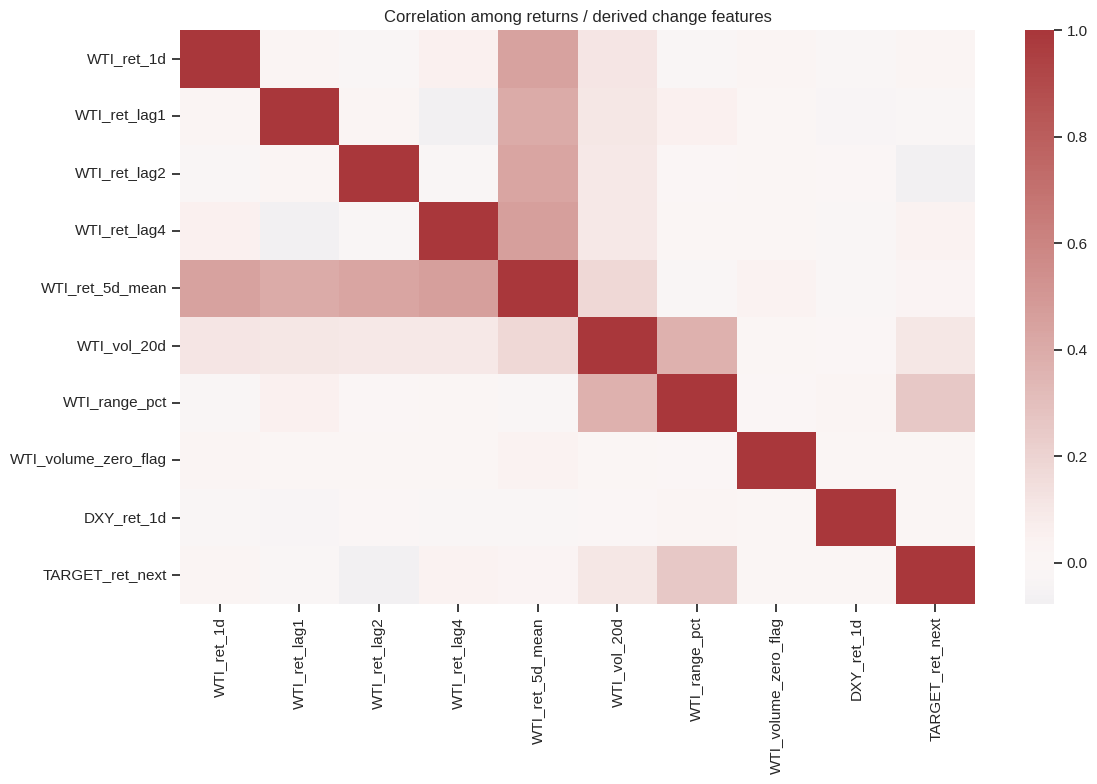

,corr_with_TARGET_ret_next
WTI_range_pct,0.254098
WTI_vol_20d,0.104504
WTI_ret_lag2,-0.074263
WTI_Low,-0.073963
WTI_Open,-0.071933
WTI_Close,-0.066921
WTI_High,-0.064411
INV_US_Crude_Stocks_kbbl,0.062435
RIG_US_Oil_Rigs,-0.061695
WTI_ret_lag4,0.044665


In [10]:
target_col = "TARGET_ret_next"
corr_cols = [c for c in df.select_dtypes(include=np.number).columns
             if c != target_col and (c.endswith("_ret_1d") or c.startswith("WTI_ret") or c in
             ["WTI_vol_20d","WTI_range_pct","WTI_volume_zero_flag","DXY_ret_1d"])]
corr_data = df[corr_cols + [target_col]].corr()
fig, ax = plt.subplots(figsize=(12,8)); sns.heatmap(corr_data, cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation among returns / derived change features"); fig.tight_layout()
fig.savefig(OUT/"10_return_correlation_heatmap.png", dpi=160); plt.show()
numeric = df.select_dtypes(include=np.number)
leak_cols = [c for c in numeric if c.startswith("TARGET_") or c.startswith("ELIGIBLE_")]
safe_candidates = [c for c in numeric if c not in leak_cols]
top = numeric[safe_candidates + [target_col]].corr()[target_col].drop(target_col).dropna().sort_values(key=abs, ascending=False).head(10)
display(top.rename("corr_with_TARGET_ret_next").to_frame())
print("Warning: univariate correlations are in-sample, non-causal, and potentially spurious; they are not feature-selection evidence.")

**Conclusion:** Correlations are exploratory only. The later feature-selection and model comparison must use training data only; no target-derived column is admitted as a feature.

## 11. Yearly return and volatility regimes

,mean_daily_return,volatility,observations,annualized_volatility
year,,,,
2014,-0.008940,0.025669,45,0.407483
2015,-0.001005,0.029613,252,0.470089
2016,0.001930,0.029952,250,0.475467
2017,0.000593,0.015783,251,0.250552
2018,-0.000943,0.019666,251,0.312180
2019,0.001402,0.021445,252,0.340436
2020,0.003564,0.060015,250,0.952715
2021,0.001988,0.022102,252,0.350863
2022,0.000721,0.030343,251,0.481677


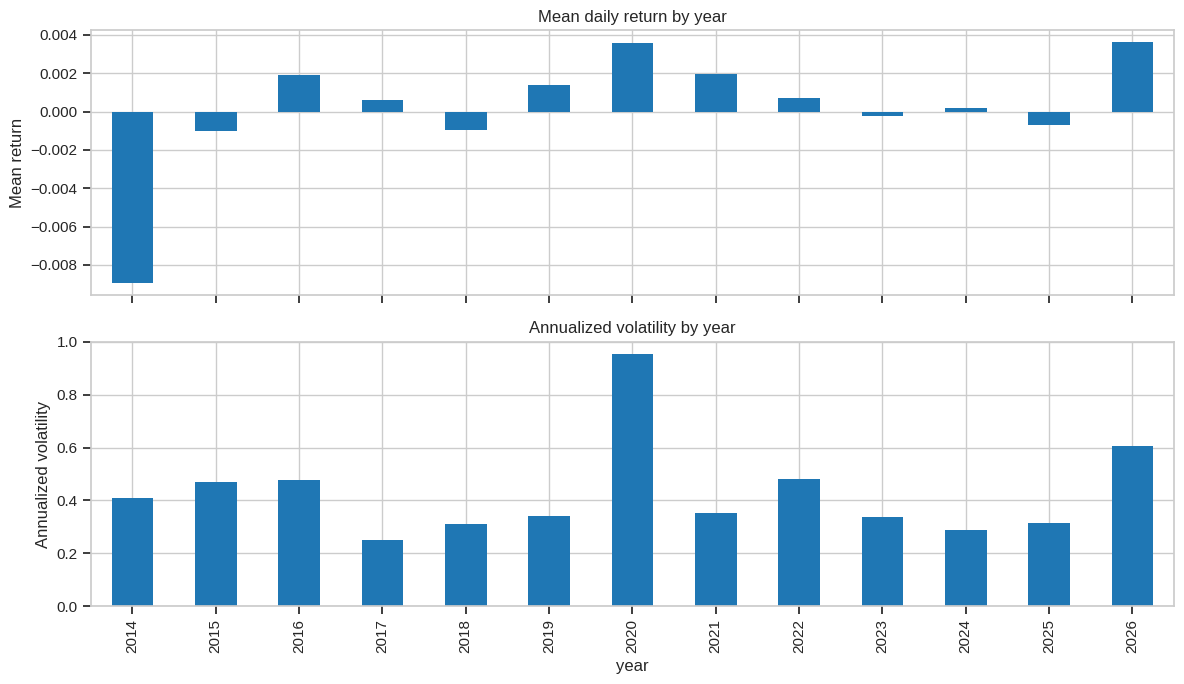

In [11]:
year_stats = df.assign(year=df.Date.dt.year).groupby("year").agg(
    mean_daily_return=("WTI_ret_1d","mean"), volatility=("WTI_ret_1d","std"), observations=("WTI_ret_1d","count"))
year_stats["annualized_volatility"] = year_stats.volatility*np.sqrt(252)
display(year_stats)
fig, axes = plt.subplots(2,1,figsize=(12,7),sharex=True)
year_stats.mean_daily_return.plot(kind="bar",ax=axes[0]); axes[0].set(title="Mean daily return by year",ylabel="Mean return")
year_stats.annualized_volatility.plot(kind="bar",ax=axes[1]); axes[1].set(title="Annualized volatility by year",ylabel="Annualized volatility")
fig.tight_layout(); fig.savefig(OUT/"11_yearly_regimes.png",dpi=160); plt.show()

**Conclusion:** Annual aggregates can conceal within-year shifts and small-sample effects. Model performance must be evaluated chronologically, not inferred from these plots.

## 12. Day-of-week and month effects (exploratory tests)

,mean,std,count
weekday,,,
Monday,-0.001060,0.030642,562
Tuesday,0.000079,0.026345,621
Wednesday,0.001128,0.033396,619
Thursday,0.002360,0.030144,607
Friday,0.001048,0.025671,603


,mean,std,count
month,,,
January,0.001383,0.024149,243
February,0.001046,0.024599,230
March,0.000311,0.043297,263
April,0.005516,0.051597,245
May,0.001569,0.028064,253
June,0.000946,0.023594,253
July,0.000091,0.023625,255
August,-0.000522,0.023267,265
September,0.000531,0.024880,246


Kruskal-Wallis weekday p: 0.8706656713492109 | month p: 0.7991543370417553


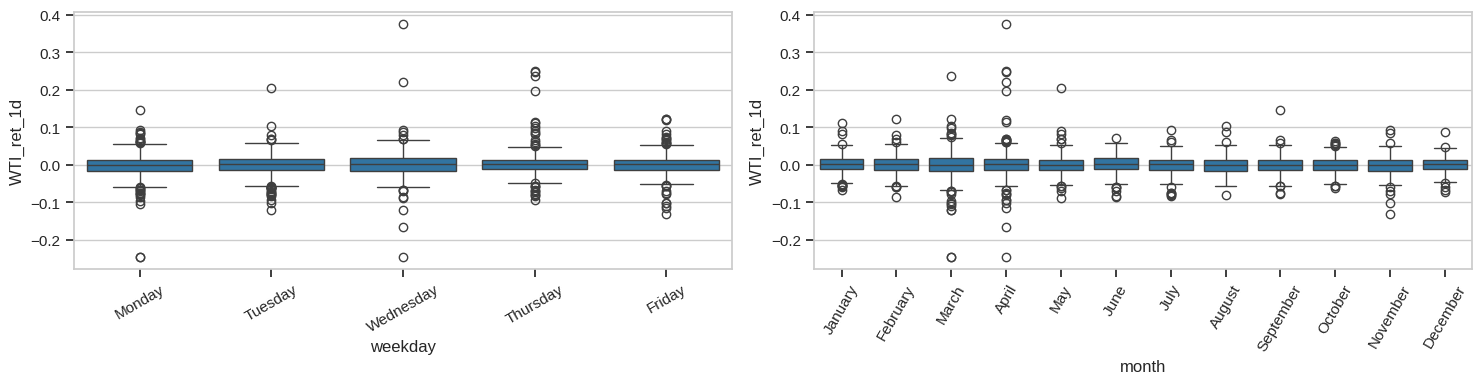

Exploratory unadjusted tests; multiple comparisons and regime shifts are not corrected.


In [12]:
season = df[["Date","WTI_ret_1d"]].dropna().copy()
season["weekday"] = season.Date.dt.day_name()
season["month"] = season.Date.dt.month_name()
weekday_groups = [g.WTI_ret_1d.values for _,g in season.groupby("weekday", sort=False)]
month_groups = [g.WTI_ret_1d.values for _,g in season.groupby("month", sort=False)]
# Explicit chronological category order
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday"]
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
season["weekday"] = pd.Categorical(season.weekday, categories=weekday_order, ordered=True)
season["month"] = pd.Categorical(season.month, categories=month_order, ordered=True)
display(season.groupby("weekday", observed=False).WTI_ret_1d.agg(["mean","std","count"]))
display(season.groupby("month", observed=False).WTI_ret_1d.agg(["mean","std","count"]))
kw_week = stats.kruskal(*[season.loc[season.weekday==d,"WTI_ret_1d"].values for d in weekday_order if (season.weekday==d).any()])
kw_month = stats.kruskal(*[season.loc[season.month==m,"WTI_ret_1d"].values for m in month_order if (season.month==m).any()])
print("Kruskal-Wallis weekday p:", kw_week.pvalue, "| month p:", kw_month.pvalue)
fig, axes = plt.subplots(1,2,figsize=(15,4))
sns.boxplot(data=season,x="weekday",y="WTI_ret_1d",ax=axes[0]); axes[0].tick_params(axis="x",rotation=30)
sns.boxplot(data=season,x="month",y="WTI_ret_1d",ax=axes[1]); axes[1].tick_params(axis="x",rotation=60)
fig.tight_layout(); fig.savefig(OUT/"12_seasonality.png",dpi=160); plt.show()
print("Exploratory unadjusted tests; multiple comparisons and regime shifts are not corrected.")

**Conclusion:** Seasonal tests are exploratory and unadjusted for multiple testing. Small p-values alone are not a trading signal.

## 13. Feature groups and eligibility sanity check

In [13]:
feature_groups = {
 "core_market": ["WTI_Open","WTI_High","WTI_Low","WTI_Close","WTI_Volume","WTI_ret_1d","WTI_ret_lag1","WTI_ret_lag2","WTI_ret_lag4","WTI_ret_5d_mean","WTI_vol_20d","WTI_range_pct","WTI_volume_zero_flag"],
 "dxy": ["DXY_Close","DXY_ret_1d","DXY_alt_source_flag","DXY_missing_flag"],
 "commodities": [c for c in df if c.startswith("CMD_")],
 "geopolitical_monthly": [c for c in df if c.startswith(("GPR_","TPU_"))],
 "eia_monthly": ["EIA_world_prod_lag3m"],
 "weekly": ["RIG_US_Oil_Rigs","INV_US_Crude_Stocks_kbbl"]}
summary=[]
for g, cols in feature_groups.items():
    cols=[c for c in cols if c in df]
    summary.append({"group":g,"columns":len(cols),"complete_rows":int(df[cols].notna().all(axis=1).sum()) if cols else 0,
                    "missing_cells":int(df[cols].isna().sum().sum()) if cols else 0})
display(pd.DataFrame(summary))
for flag in ["ELIGIBLE_core","ELIGIBLE_extended"]:
    if flag in df: print(flag, "rows=1:",int((df[flag]==1).sum()),"| date range:",df.loc[df[flag]==1,"Date"].min(),"to",df.loc[df[flag]==1,"Date"].max())
print("No rows or values are imputed by this notebook.")

,group,columns,complete_rows,missing_cells
0,core_market,13,2994,51
1,dxy,4,3001,28
2,commodities,7,2894,732
3,geopolitical_monthly,4,3011,20
4,eia_monthly,1,2970,46
5,weekly,2,3016,0


ELIGIBLE_core rows=1: 2980 | date range: 2014-11-17 00:00:00 to 2026-10-07 00:00:00
ELIGIBLE_extended rows=1: 2840 | date range: 2015-01-02 00:00:00 to 2026-05-01 00:00:00
No rows or values are imputed by this notebook.


**Conclusion:** Eligibility is taken as supplied, then verified empirically. Extended coverage and feature groups are not presumed trustworthy simply because a row is complete.

## 14. Feature sets, splits, and leakage guardrails

In [14]:
TARGET_RET, TARGET_CLOSE, TARGET_UP = "TARGET_ret_next", "TARGET_close_next", "TARGET_up_next"
META = {"Date", TARGET_RET, TARGET_CLOSE, TARGET_UP, "ELIGIBLE_core", "ELIGIBLE_extended"}
# Exclude target/meta columns, and exclude current close from return models? It is known at after-close cutoff,
# but its level is scale/nonstationary; retain only for price reconstruction and baselines, not return feature input.
CORE_FEATURES = [c for c in ["WTI_ret_1d","WTI_ret_lag1","WTI_ret_lag2","WTI_ret_lag4","WTI_ret_5d_mean","WTI_vol_20d","WTI_range_pct","WTI_volume_zero_flag","DXY_ret_1d","DXY_alt_source_flag","DXY_missing_flag","RIG_US_Oil_Rigs","INV_US_Crude_Stocks_kbbl"] if c in df]
EXTENDED_FEATURES = CORE_FEATURES + [c for c in df if c.startswith(("CMD_","GPR_","TPU_")) or c=="EIA_world_prod_lag3m"]
EXTENDED_FEATURES = list(dict.fromkeys(c for c in EXTENDED_FEATURES if c not in META and not c.startswith("TARGET_")))
assert not (set(CORE_FEATURES)|set(EXTENDED_FEATURES)) & META
assert not any(c.startswith("TARGET_") for c in CORE_FEATURES+EXTENDED_FEATURES)
assert "Date" not in CORE_FEATURES+EXTENDED_FEATURES
print("Core features:", CORE_FEATURES)
print("Extended features:", EXTENDED_FEATURES)
def eligible_frame(data, eligibility, features):
    mask = (data[eligibility] == 1) & data[TARGET_RET].notna() & data[TARGET_CLOSE].notna() & data[TARGET_UP].notna()
    # Respect no-imputation rule: model only rows complete on the chosen feature set.
    mask &= data[features].notna().all(axis=1)
    return data.loc[mask].copy().sort_values("Date").reset_index(drop=True)
def split_frame(data):
    train = data[data.Date <= "2021-12-31"].copy()
    val = data[(data.Date >= "2022-01-01") & (data.Date <= "2023-12-31")].copy()
    test = data[data.Date >= "2024-01-01"].copy()
    for name, part in [("train",train),("validation",val),("test",test)]:
        print(f"{name:10s} n={len(part):4d} dates={part.Date.min()} -> {part.Date.max()}")
    return train,val,test
core = eligible_frame(df,"ELIGIBLE_core",CORE_FEATURES)
extended = eligible_frame(df,"ELIGIBLE_extended",EXTENDED_FEATURES)
print("\nCORE"); core_train,core_val,core_test=split_frame(core)
print("\nEXTENDED"); ext_train,ext_val,ext_test=split_frame(extended)
if len(core_train)==0 or len(core_val)==0 or len(core_test)==0: raise ValueError("Core split is empty; inspect eligibility/date assumptions.")
if len(ext_train)==0 or len(ext_val)==0 or len(ext_test)==0: print("WARNING: an extended split is empty; extended model evaluation will be limited.")

Core features: ['WTI_ret_1d', 'WTI_ret_lag1', 'WTI_ret_lag2', 'WTI_ret_lag4', 'WTI_ret_5d_mean', 'WTI_vol_20d', 'WTI_range_pct', 'WTI_volume_zero_flag', 'DXY_ret_1d', 'DXY_alt_source_flag', 'DXY_missing_flag', 'RIG_US_Oil_Rigs', 'INV_US_Crude_Stocks_kbbl']
Extended features: ['WTI_ret_1d', 'WTI_ret_lag1', 'WTI_ret_lag2', 'WTI_ret_lag4', 'WTI_ret_5d_mean', 'WTI_vol_20d', 'WTI_range_pct', 'WTI_volume_zero_flag', 'DXY_ret_1d', 'DXY_alt_source_flag', 'DXY_missing_flag', 'RIG_US_Oil_Rigs', 'INV_US_Crude_Stocks_kbbl', 'CMD_brent_lag1', 'CMD_urals_lag1', 'CMD_espo_lag1', 'CMD_ttf_lag1', 'CMD_wheat_lag1', 'CMD_urea_lag1', 'CMD_missing_flag', 'GPR_total_lag1m', 'GPR_threats_lag1m', 'GPR_acts_lag1m', 'TPU_lag1m', 'EIA_world_prod_lag3m']

CORE
train      n=1785 dates=2014-11-17 00:00:00 -> 2021-12-31 00:00:00
validation n= 501 dates=2022-01-03 00:00:00 -> 2023-12-29 00:00:00
test       n= 694 dates=2024-01-02 00:00:00 -> 2026-10-07 00:00:00

EXTENDED
train      n=1754 dates=2015-01-02 00:00:00 ->

**Conclusion:** Train is through 2021, validation is 2022–2023, and test starts 2024. Feature completeness is required but NaNs are not filled. Current close is used for persistence and price reconstruction only, not as a return-model input. This split is chronological; timing validity of weekly/monthly fields remains an assumption.

## 15. Baselines and evaluation helpers

In [15]:
def rmse(y, p): return float(np.sqrt(mean_squared_error(y,p)))
def max_drawdown(equity):
    if len(equity)==0: return np.nan
    peak=np.maximum.accumulate(equity)
    dd=equity/np.where(peak==0,1,peak)-1
    return float(np.min(dd))
def dm_test(loss_model, loss_base):
    # Approximate paired loss-difference t-test; no HAC correction.
    d=np.asarray(loss_base)-np.asarray(loss_model)
    d=d[np.isfinite(d)]
    if len(d)<2 or np.std(d,ddof=1)==0: return np.nan,np.nan
    t=float(np.mean(d)/(np.std(d,ddof=1)/np.sqrt(len(d))))
    return t, float(2*stats.t.sf(abs(t),df=len(d)-1))
def regression_metrics(part, pred, label):
    y=part[TARGET_RET].to_numpy(); p=np.asarray(pred)
    price_true=part[TARGET_CLOSE].to_numpy()
    price_pred=part.WTI_Close.to_numpy()*(1+p)
    persistence_price=part.WTI_Close.to_numpy()
    zero_mae=mean_absolute_error(y,np.zeros(len(y)))
    persist_ret=part.WTI_ret_1d.to_numpy()
    persist_mae=mean_absolute_error(y,persist_ret)
    return {"model":label,"n_test":len(y),"return_MAE":mean_absolute_error(y,p),"return_RMSE":rmse(y,p),
            "price_MAE":mean_absolute_error(price_true,price_pred),"price_RMSE":rmse(price_true,price_pred),
            "price_persistence_MAE":mean_absolute_error(price_true,persistence_price),
            "return_zero_MAE":zero_mae,"return_persistence_MAE":persist_mae,
            "MAE_improvement_vs_persistence_pct":100*(persist_mae-mean_absolute_error(y,p))/persist_mae if persist_mae else np.nan}
def baseline_predictions(part):
    return {"ZeroReturn":np.zeros(len(part)),
            "PreviousDayReturn":part.WTI_ret_1d.fillna(0).to_numpy(),
            "SeasonalNaive5dMean":part.WTI_ret_1d.rolling(5,min_periods=1).mean().to_numpy()}
def direction_metrics(y,p):
    p=(np.asarray(p)>=.5).astype(int); y=np.asarray(y).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,p,labels=[0,1]).ravel()
    return {"accuracy":accuracy_score(y,p),"balanced_accuracy":balanced_accuracy_score(y,p),
            "precision":precision_score(y,p,zero_division=0),"recall":recall_score(y,p,zero_division=0),
            "TN":tn,"FP":fp,"FN":fn,"TP":tp}
print("Metric helpers ready.")

Metric helpers ready.


**Conclusion:** Baselines are evaluated on exactly the same test rows as each model. Paired tests below are approximate; dependence in daily losses can invalidate an ordinary t-test.

## 16. Walk-forward robustness check (expanding window, gap=1)

In [16]:
def walk_forward_zero_baseline(data, features, n_splits=5):
    # Expanding-window splits; gap=1 prevents the final training target from abutting validation.
    X=data[features]; y=data[TARGET_RET].to_numpy()
    tscv=TimeSeriesSplit(n_splits=n_splits,gap=1)
    rows=[]
    for fold,(tr,va) in enumerate(tscv.split(X),1):
        rows.append({"fold":fold,"train_start":str(data.Date.iloc[tr[0]].date()),"train_end":str(data.Date.iloc[tr[-1]].date()),
                     "val_start":str(data.Date.iloc[va[0]].date()),"val_end":str(data.Date.iloc[va[-1]].date()),
                     "n_train":len(tr),"n_val":len(va),"zero_MAE":mean_absolute_error(y[va],np.zeros(len(va))),
                     "previous_return_MAE":mean_absolute_error(y[va],data.WTI_ret_1d.iloc[va].to_numpy())})
    return pd.DataFrame(rows)
display(walk_forward_zero_baseline(core,CORE_FEATURES))
display(walk_forward_zero_baseline(extended,EXTENDED_FEATURES))

,fold,train_start,train_end,val_start,val_end,n_train,n_val,zero_MAE,previous_return_MAE
0,1,2014-11-17,2016-11-09,2016-11-14,2018-11-01,499,496,0.012585,0.018492
1,2,2014-11-17,2018-10-31,2018-11-02,2020-11-02,995,496,0.023083,0.033322
2,3,2014-11-17,2020-10-30,2020-11-03,2022-10-21,1491,496,0.019550,0.027966
3,4,2014-11-17,2022-10-20,2022-10-24,2024-10-14,1987,496,0.016423,0.022447
4,5,2014-11-17,2024-10-11,2024-10-15,2026-10-07,2483,496,0.019924,0.028874


,fold,train_start,train_end,val_start,val_end,n_train,n_val,zero_MAE,previous_return_MAE
0,1,2015-01-02,2016-11-18,2016-11-22,2018-10-09,474,473,0.012469,0.018375
1,2,2015-01-02,2018-10-08,2018-10-10,2020-09-04,947,473,0.022773,0.032690
2,3,2015-01-02,2020-09-03,2020-09-08,2022-07-25,1420,473,0.019445,0.027891
3,4,2015-01-02,2022-07-22,2022-07-26,2024-06-11,1893,473,0.016991,0.023318
4,5,2015-01-02,2024-06-10,2024-06-12,2026-05-01,2366,473,0.018267,0.027027


**Conclusion:** This is a baseline robustness check, not a full hyperparameter search. The held-out final test remains reserved for one final evaluation.

## 17. Model training: validation-only tuning, final test untouched

In [17]:
from sklearn.base import BaseEstimator
try:
    from xgboost import XGBRegressor, XGBClassifier
    HAS_XGB=True
except Exception as e:
    print("XGBoost unavailable:",e); HAS_XGB=False
try:
    from lightgbm import LGBMRegressor, LGBMClassifier
    HAS_LGBM=True
except Exception as e:
    print("LightGBM unavailable:",e); HAS_LGBM=False

def reg_candidates():
    models = {
      "Ridge": (Pipeline([("scale",StandardScaler()),("model",Ridge())]), {"model__alpha":[0.1,1.0,10.0]}),
      "Lasso": (Pipeline([("scale",StandardScaler()),("model",Lasso(max_iter=20000,random_state=SEED))]), {"model__alpha":[1e-5,1e-4,1e-3]}),
      "ElasticNet": (Pipeline([("scale",StandardScaler()),("model",ElasticNet(max_iter=20000,random_state=SEED))]), {"model__alpha":[1e-4,1e-3],"model__l1_ratio":[.2,.8]}),
      "RandomForest": (RandomForestRegressor(random_state=SEED,n_jobs=-1), {"n_estimators":[300],"max_depth":[3,8,None],"min_samples_leaf":[5,20]}),
      "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=SEED), {"learning_rate":[.03,.1],"max_iter":[100],"max_leaf_nodes":[7,15],"l2_regularization":[0,1]})
    }
    if HAS_XGB: models["XGBoost"]=(XGBRegressor(random_state=SEED,n_jobs=4,objective="reg:squarederror",verbosity=0),{"n_estimators":[200],"max_depth":[2,3],"learning_rate":[.03,.08],"subsample":[.8],"colsample_bytree":[.8]})
    if HAS_LGBM: models["LightGBM"]=(LGBMRegressor(random_state=SEED,verbosity=-1,n_jobs=4),{"n_estimators":[200],"num_leaves":[7,15],"learning_rate":[.03,.08]})
    return models
def tune_regressor(train,val,features):
    results={}
    for name,(est,grid) in reg_candidates().items():
        best=None
        for params in ParameterGrid(grid):
            m=clone(est).set_params(**params)
            m.fit(train[features],train[TARGET_RET])
            pred=m.predict(val[features])
            score=mean_absolute_error(val[TARGET_RET],pred)
            if best is None or score<best["val_mae"]:
                best={"val_mae":score,"params":params,"estimator":m}
        results[name]=best
        print(name,"validation MAE",round(best["val_mae"],6),"params",best["params"])
    return results
core_reg_val=tune_regressor(core_train,core_val,CORE_FEATURES)
ext_reg_val=tune_regressor(ext_train,ext_val,EXTENDED_FEATURES) if len(ext_train) and len(ext_val) else {}
print("Search spaces are explicit above. Test data has not been used for tuning.")

Ridge validation MAE 0.020667 params {'model__alpha': 10.0}
Lasso validation MAE 0.020514 params {'model__alpha': 0.001}
ElasticNet validation MAE 0.02055 params {'model__alpha': 0.001, 'model__l1_ratio': 0.8}
RandomForest validation MAE 0.020566 params {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 300}
HistGradientBoosting validation MAE 0.021205 params {'l2_regularization': 0, 'learning_rate': 0.03, 'max_iter': 100, 'max_leaf_nodes': 7}
XGBoost validation MAE 0.020931 params {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}
LightGBM validation MAE 0.021737 params {'learning_rate': 0.03, 'n_estimators': 200, 'num_leaves': 7}
Ridge validation MAE 0.028834 params {'model__alpha': 10.0}
Lasso validation MAE 0.020657 params {'model__alpha': 0.001}
ElasticNet validation MAE 0.020738 params {'model__alpha': 0.001, 'model__l1_ratio': 0.8}
RandomForest validation MAE 0.020907 params {'max_depth': 3, 'min_samples_leaf': 20, 'n_est

**Conclusion:** Hyperparameters are selected using validation MAE only. StandardScaler is inside the linear-model pipeline, so it is fitted on the training partition only. The search is intentionally small; validation selection can still overfit.

## 18. Final regression evaluation (fit train + validation; test once)

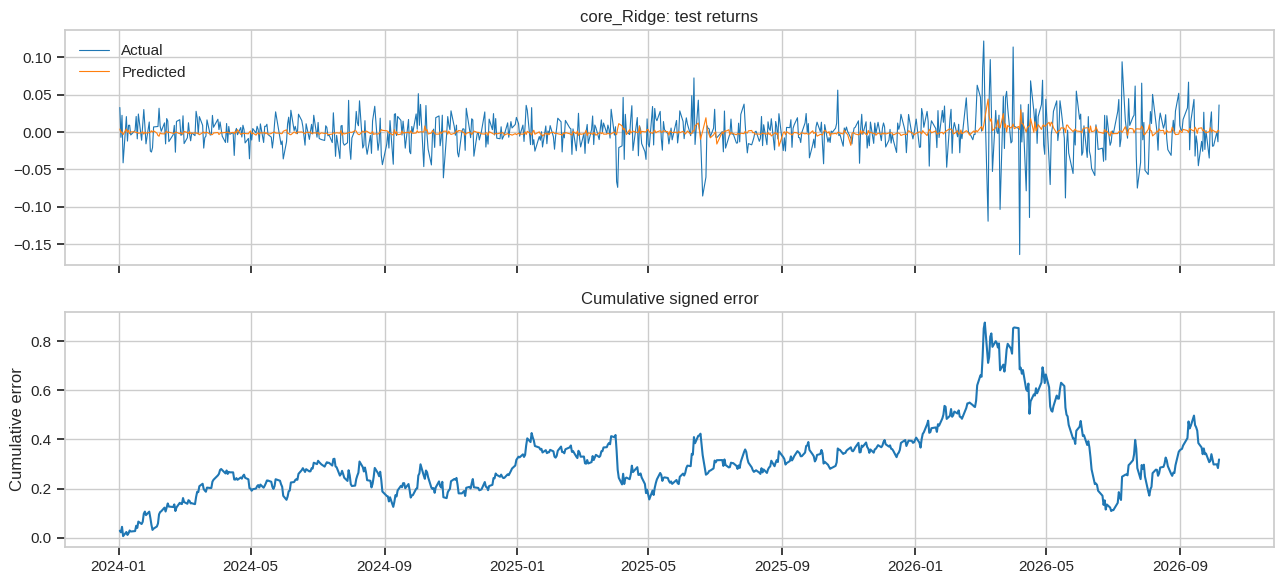

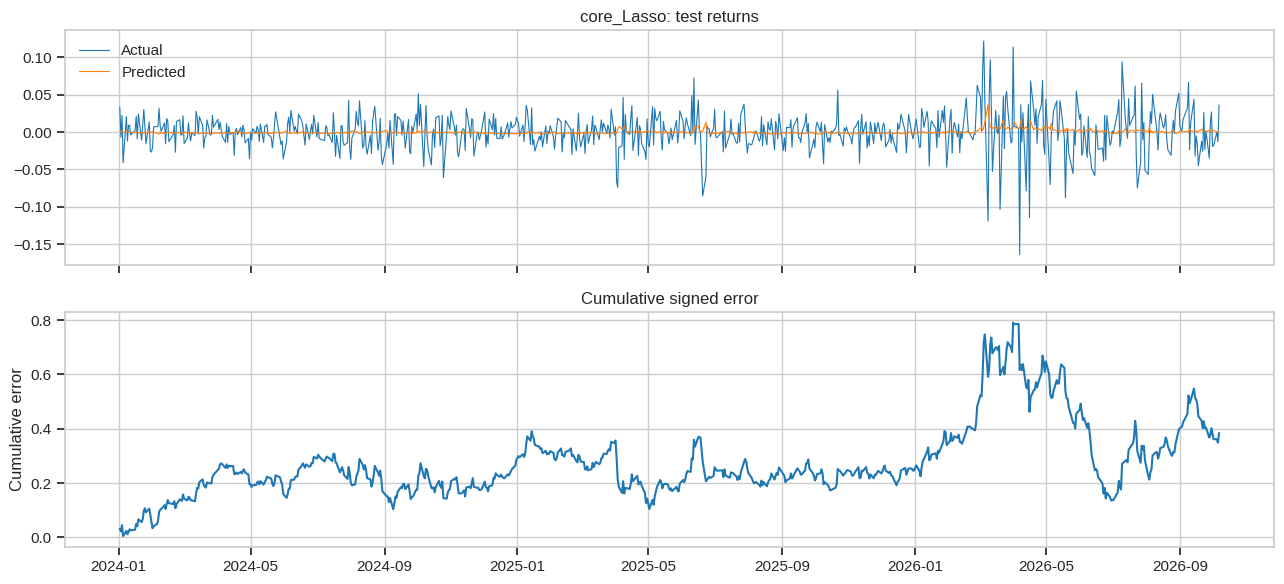

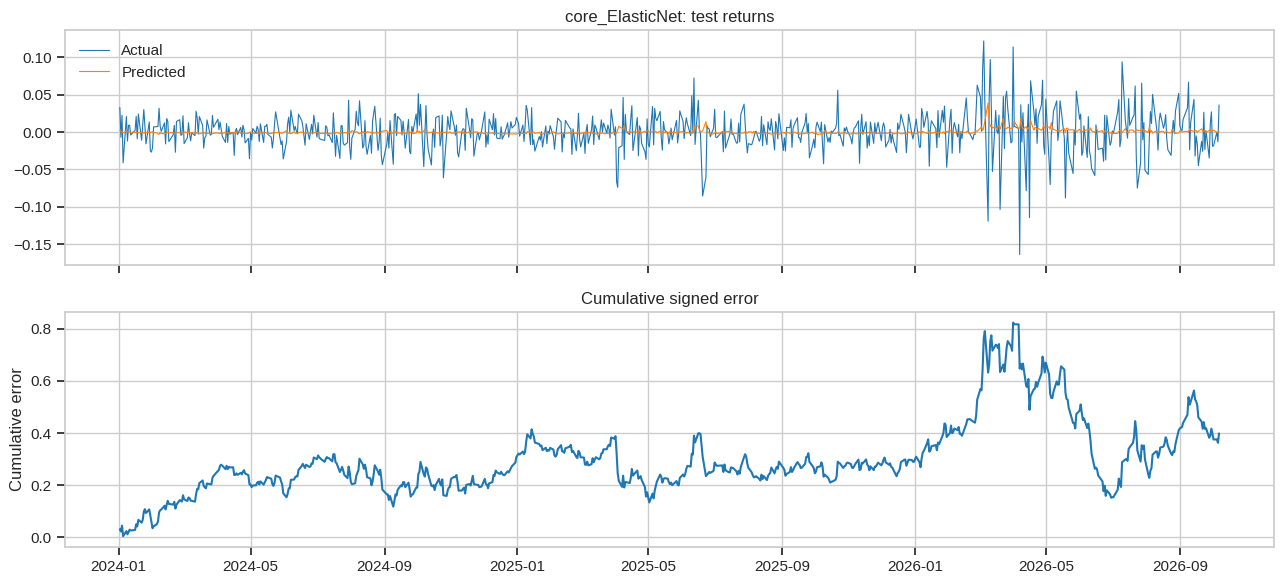

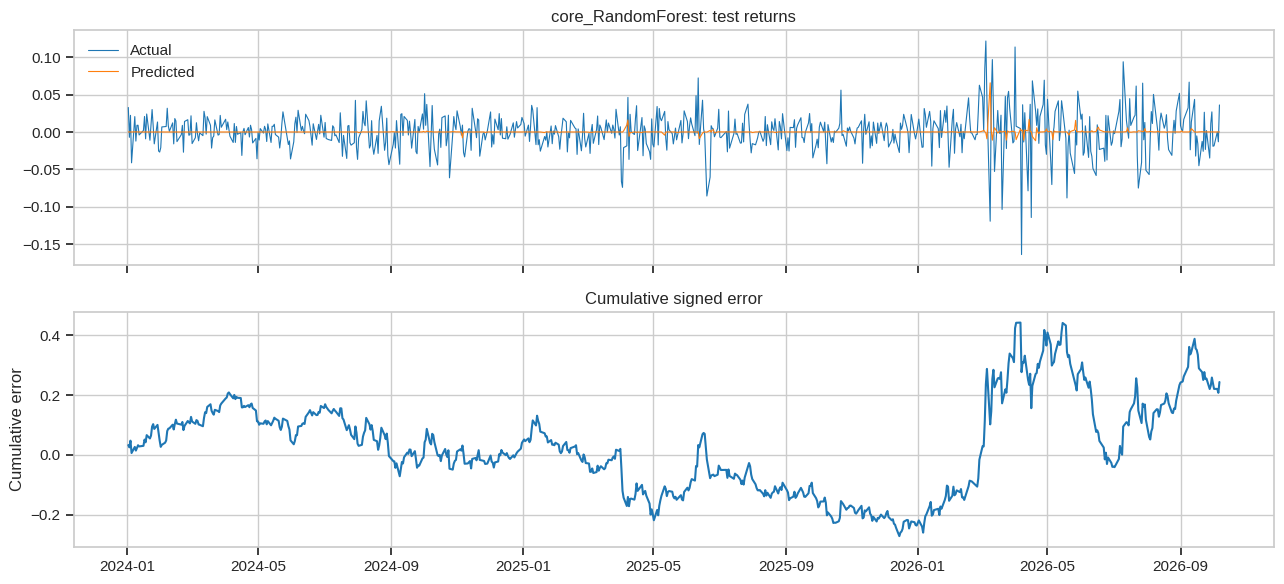

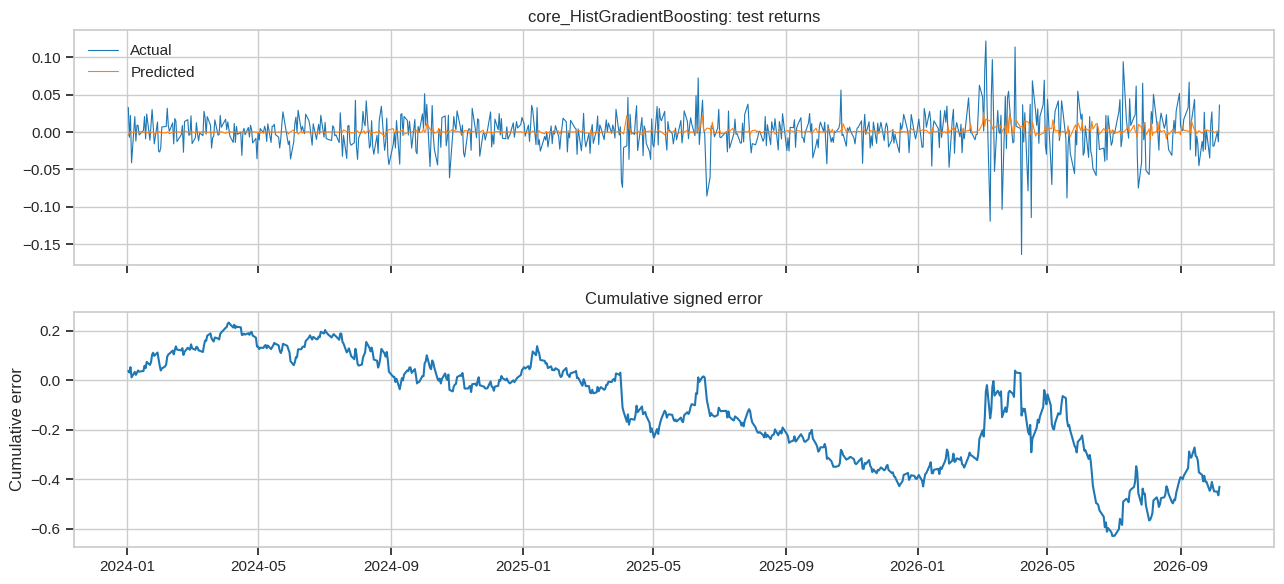

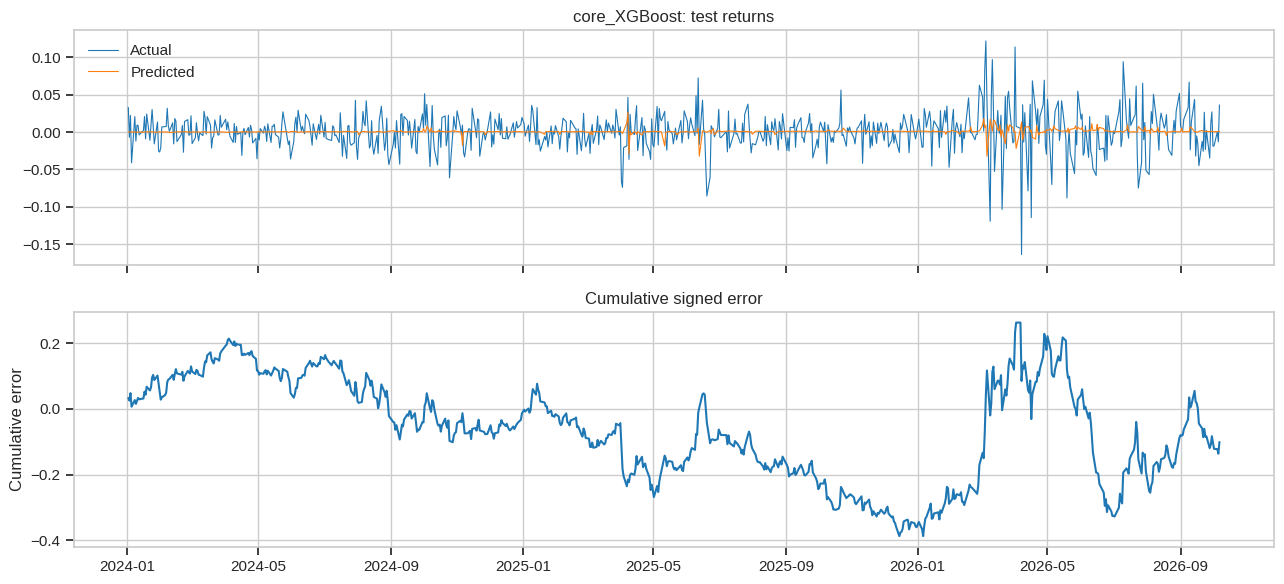

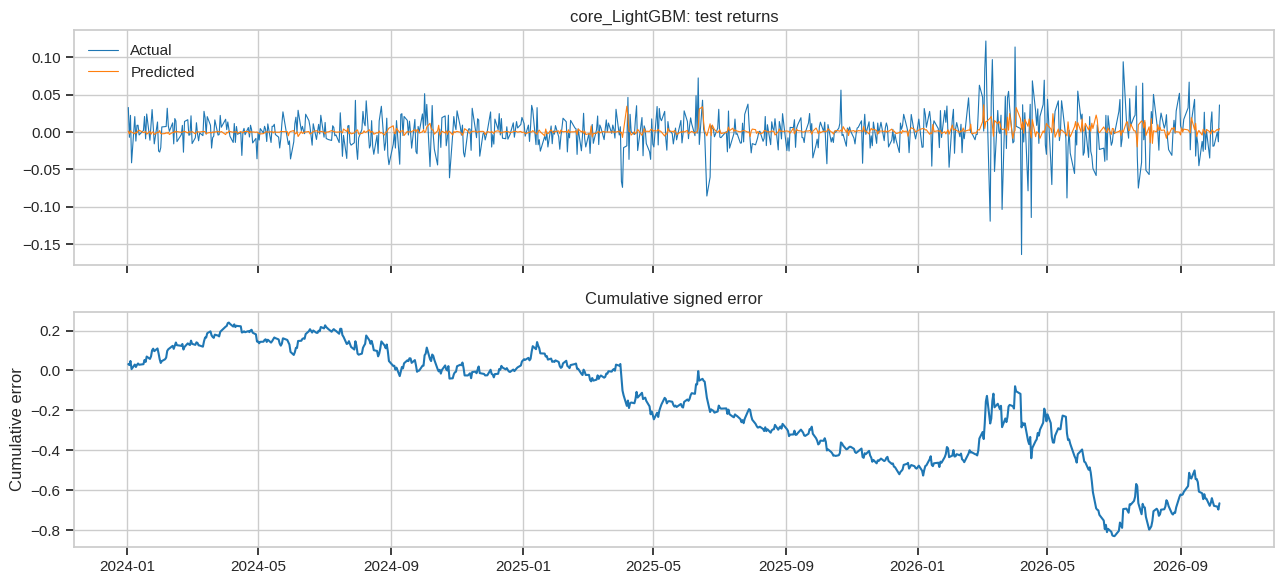

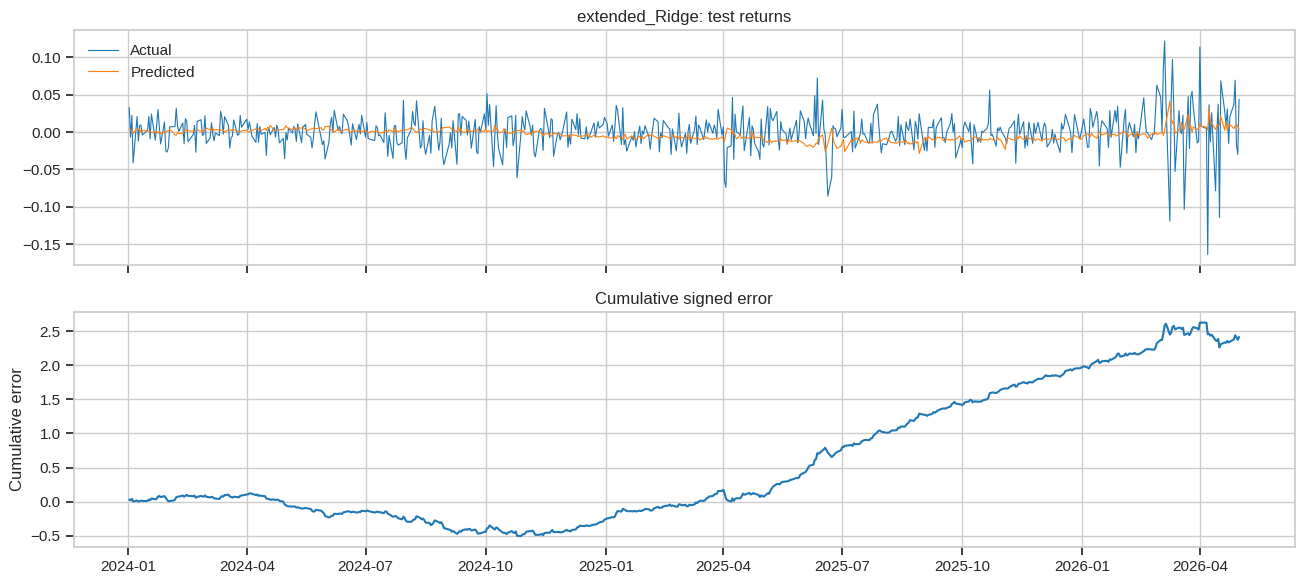

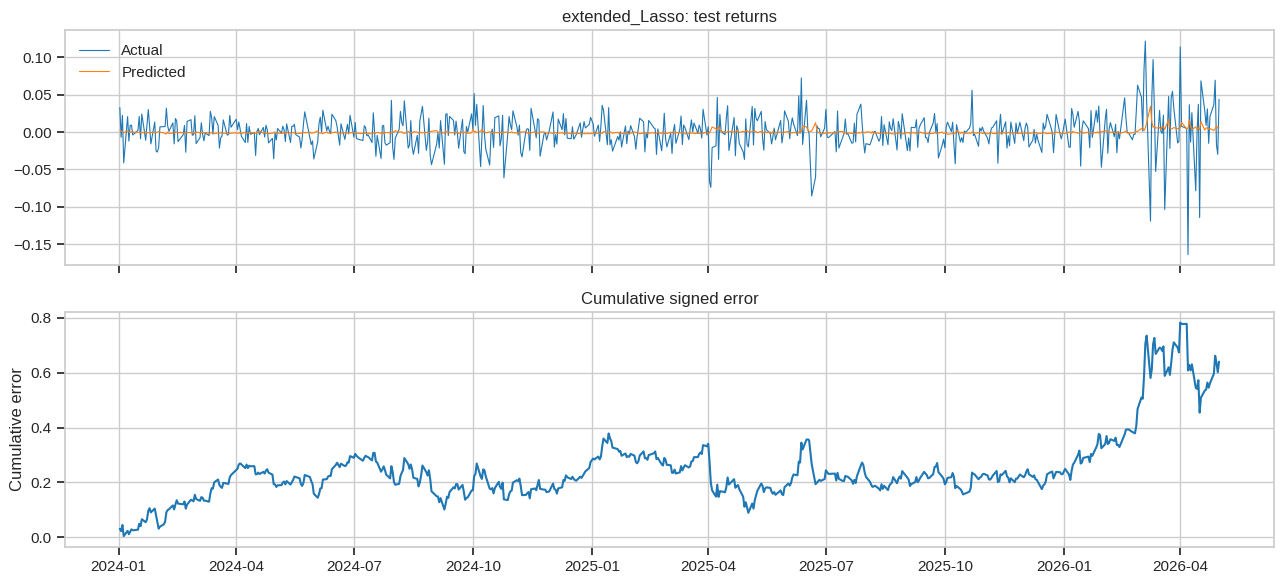

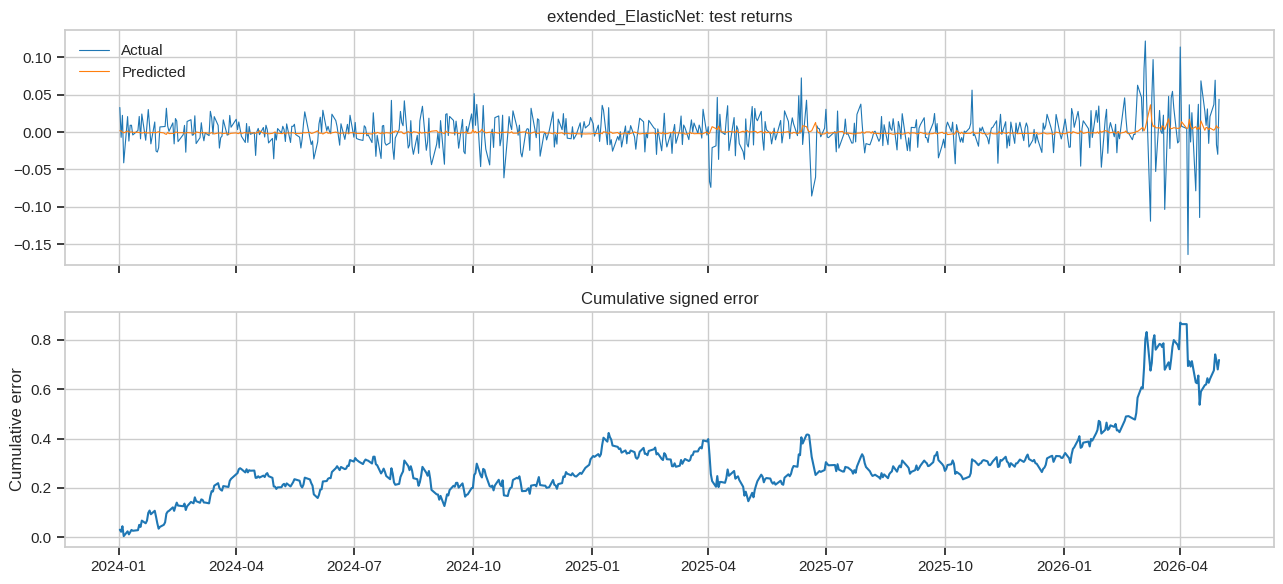

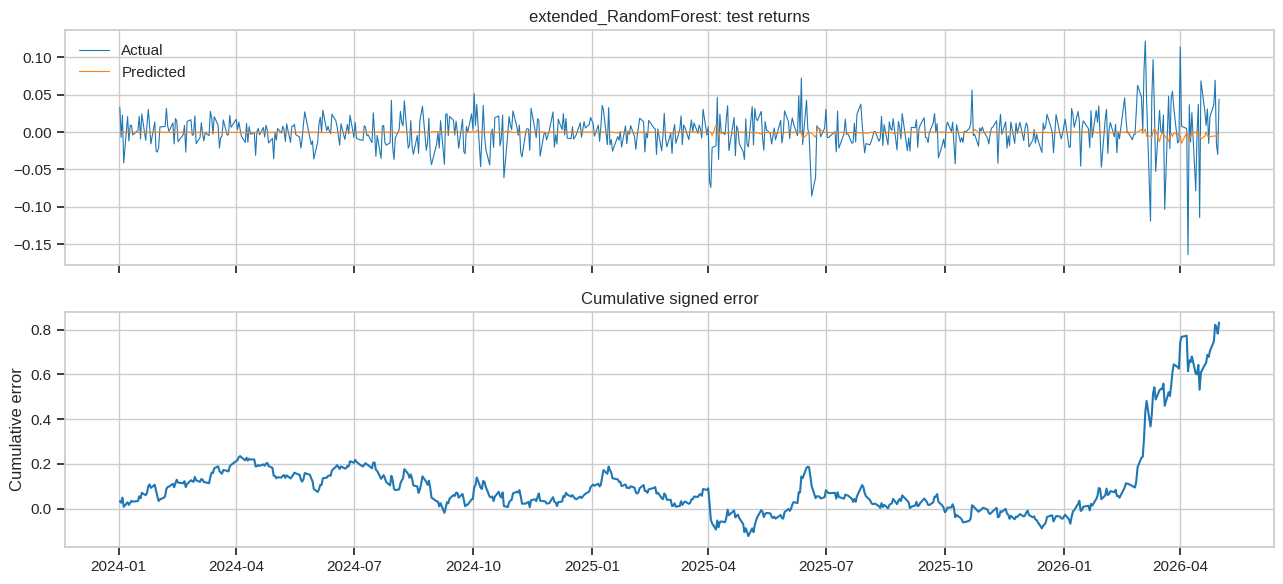

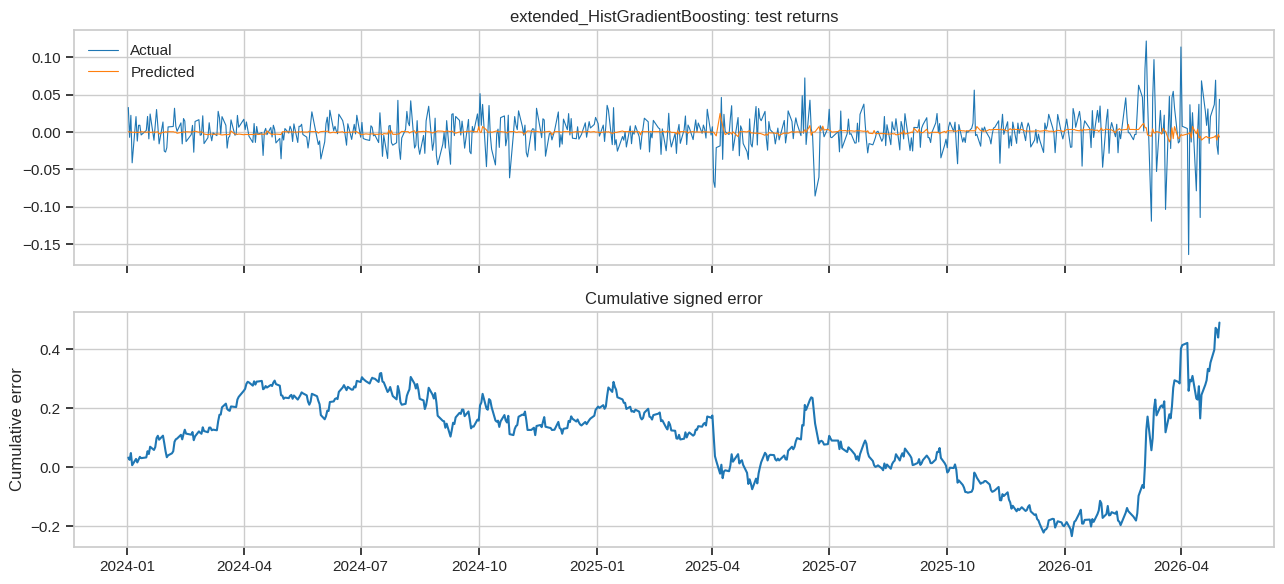

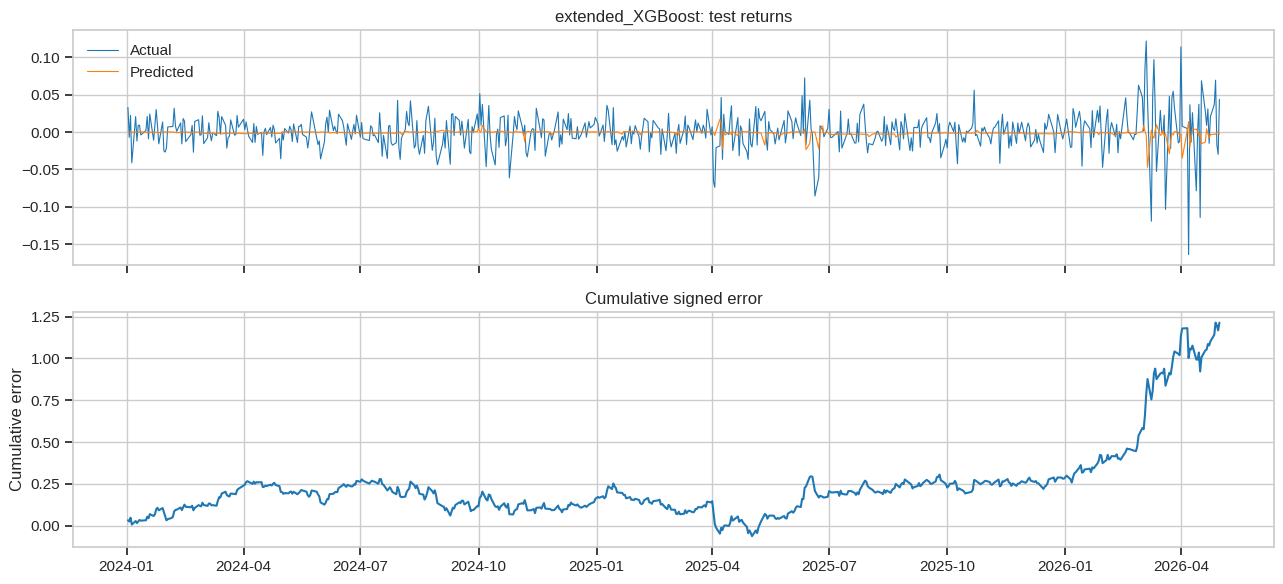

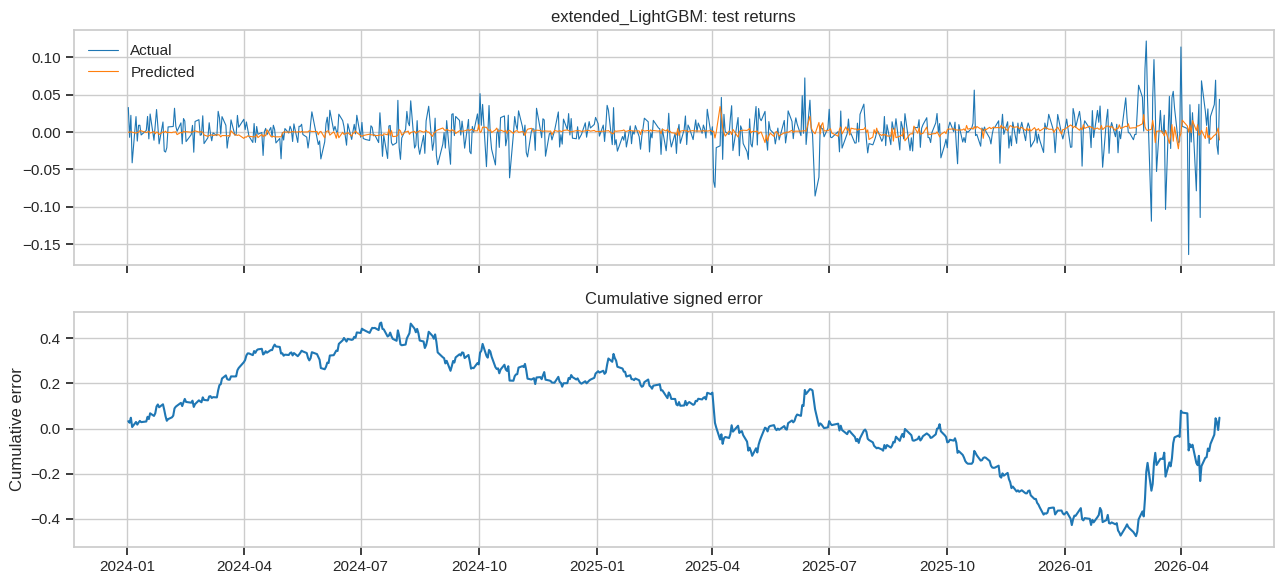

,model,n_test,return_MAE,return_RMSE,price_MAE,price_RMSE,price_persistence_MAE,return_zero_MAE,return_persistence_MAE,MAE_improvement_vs_persistence_pct,DM_t_vs_zero,DM_p_vs_zero,DM_t_vs_prev_return,DM_p_vs_prev_return
0,core_Ridge,694,0.018541,0.026386,1.431460,2.217076,1.421700,0.018398,0.026621,30.349467,-0.830003,0.406823,6.102049,1.741774e-09
1,core_Lasso,694,0.018449,0.026302,1.425636,2.213469,1.421700,0.018398,0.026621,30.698273,-0.803989,0.421679,6.210924,9.079503e-10
2,core_ElasticNet,694,0.018457,0.026326,1.426275,2.215747,1.421700,0.018398,0.026621,30.665191,-0.825507,0.409368,6.192976,1.011570e-09
3,core_RandomForest,694,0.018553,0.026754,1.436795,2.260085,1.421700,0.018398,0.026621,30.307329,-1.271880,0.203842,6.055985,2.287784e-09
4,core_HistGradientBoosting,694,0.018304,0.025946,1.413407,2.183609,1.421700,0.018398,0.026621,31.241774,0.398285,0.690543,6.360845,3.643648e-10
5,core_XGBoost,694,0.018523,0.026492,1.436321,2.243643,1.421700,0.018398,0.026621,30.420345,-1.720786,0.085736,6.357299,3.723973e-10
6,core_LightGBM,694,0.018456,0.026126,1.426055,2.196513,1.421700,0.018398,0.026621,30.669724,-0.265701,0.790549,6.243129,7.474097e-10
7,core_ZeroReturn,694,0.018398,0.026046,1.421700,2.183718,1.421700,0.018398,0.026621,30.887220,NaN,NaN,NaN,NaN
8,core_PreviousDayReturn,694,0.026621,0.036633,2.054398,3.055597,1.421700,0.018398,0.026621,0.000000,NaN,NaN,NaN,NaN
9,core_SeasonalNaive5dMean,694,0.020533,0.028324,1.586958,2.377806,1.421700,0.018398,0.026621,22.869674,NaN,NaN,NaN,NaN


In [18]:
def final_regression_eval(data, features, train, val, test, tuned, set_name):
    records=[]; fitted={}
    for name,info in tuned.items():
        model=clone(info["estimator"])
        fitdata=pd.concat([train,val]).sort_values("Date")
        model.fit(fitdata[features],fitdata[TARGET_RET])
        pred=model.predict(test[features]); fitted[name]=model
        row=regression_metrics(test,pred,f"{set_name}_{name}"); records.append(row)
        # paired approximate DM on squared-error loss vs zero and persistence return baseline
        y=test[TARGET_RET].to_numpy()
        for bname,bpred in [("zero",np.zeros(len(test))),("prev_return",test.WTI_ret_1d.to_numpy())]:
            t,pv=dm_test((y-pred)**2,(y-bpred)**2)
            row[f"DM_t_vs_{bname}"]=t; row[f"DM_p_vs_{bname}"]=pv
        records[-1]=row
        plot_predictions(test,pred,f"{set_name}_{name}")
    # Baselines on the same rows
    for bname,pred in baseline_predictions(test).items():
        records.append(regression_metrics(test,pred,f"{set_name}_{bname}"))
    # Price persistence: return forecast = 0 gives predicted price equal current close.
    return pd.DataFrame(records), fitted
def plot_predictions(test,pred,label):
    y=test[TARGET_RET].to_numpy()
    fig,axes=plt.subplots(2,1,figsize=(13,6),sharex=True)
    axes[0].plot(test.Date,y,label="Actual",lw=.8); axes[0].plot(test.Date,pred,label="Predicted",lw=.8); axes[0].legend()
    axes[0].set_title(f"{label}: test returns")
    err=y-np.asarray(pred); axes[1].plot(test.Date,np.cumsum(err)); axes[1].set_title("Cumulative signed error"); axes[1].set_ylabel("Cumulative error")
    fig.tight_layout(); fig.savefig(OUT/f"pred_{label}.png",dpi=140); plt.show()
core_reg_results,core_models=final_regression_eval(core,CORE_FEATURES,core_train,core_val,core_test,core_reg_val,"core")
ext_reg_results,ext_models=final_regression_eval(extended,EXTENDED_FEATURES,ext_train,ext_val,ext_test,ext_reg_val,"extended") if ext_reg_val and len(ext_test) else (pd.DataFrame(),{})
reg_results=pd.concat([core_reg_results,ext_reg_results],ignore_index=True)
display(reg_results)
reg_results.to_csv(OUT/"regression_results.csv",index=False)

**Conclusion:** The test set is evaluated only after validation tuning, with the selected model refit on train + validation. The price MAE/RMSE reconstruction uses `Close(t) * (1 + predicted return)` as requested; negative/near-zero prices make percentage-return interpretations problematic.

## 19. Direction classifiers (validation-only selection)

In [19]:
def classifier_candidates():
    return {
      "LogisticRegression":(Pipeline([("scale",StandardScaler()),("model",LogisticRegression(max_iter=5000,random_state=SEED))]),
                            {"model__C":[.1,1,10]}),
      "RandomForestClassifier":(RandomForestClassifier(random_state=SEED,n_jobs=-1,class_weight="balanced"),
                                {"n_estimators":[300],"max_depth":[3,8,None],"min_samples_leaf":[5,20]}),
      "HistGradientBoostingClassifier":(HistGradientBoostingClassifier(random_state=SEED),
                                {"learning_rate":[.03,.1],"max_iter":[100],"max_leaf_nodes":[7,15]})}
def tune_classifier(train,val,features):
    out={}
    for name,(est,grid) in classifier_candidates().items():
        best=None
        for params in ParameterGrid(grid):
            m=clone(est).set_params(**params); m.fit(train[features],train[TARGET_UP].astype(int))
            prob=m.predict_proba(val[features])[:,1] if hasattr(m,"predict_proba") else m.predict(val[features])
            pred=(prob>=.5).astype(int)
            score=balanced_accuracy_score(val[TARGET_UP].astype(int),pred)
            if best is None or score>best["val_bal_acc"]:
                best={"val_bal_acc":score,"params":params,"estimator":m}
        out[name]=best; print(name,"validation balanced accuracy",round(best["val_bal_acc"],4),best["params"])
    return out
core_clf_val=tune_classifier(core_train,core_val,CORE_FEATURES)
ext_clf_val=tune_classifier(ext_train,ext_val,EXTENDED_FEATURES) if len(ext_train) and len(ext_val) else {}

LogisticRegression validation balanced accuracy 0.494 {'model__C': 0.1}
RandomForestClassifier validation balanced accuracy 0.5112 {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 300}
HistGradientBoostingClassifier validation balanced accuracy 0.492 {'learning_rate': 0.03, 'max_iter': 100, 'max_leaf_nodes': 15}
LogisticRegression validation balanced accuracy 0.5285 {'model__C': 0.1}
RandomForestClassifier validation balanced accuracy 0.4998 {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 300}
HistGradientBoostingClassifier validation balanced accuracy 0.5244 {'learning_rate': 0.03, 'max_iter': 100, 'max_leaf_nodes': 15}


## 20. Final direction evaluation and paired baseline test

In [20]:
def eval_classifiers(train,val,test,features,tuned,set_name):
    rows=[]; fitted={}
    fitdata=pd.concat([train,val]).sort_values("Date"); y=test[TARGET_UP].astype(int).to_numpy()
    majority=int(train[TARGET_UP].mean()>=.5)
    baselines={"MajorityClass":np.full(len(test),majority,dtype=int),
               "PreviousReturnSign":(test.WTI_ret_1d.to_numpy()>0).astype(int)}
    for name,info in tuned.items():
        m=clone(info["estimator"]); m.fit(fitdata[features],fitdata[TARGET_UP].astype(int))
        pred=(m.predict_proba(test[features])[:,1]>=.5).astype(int); fitted[name]=m
        row={"model":f"{set_name}_{name}",**direction_metrics(y,pred)}
        for bname,bpred in baselines.items():
            # paired bootstrap CI for accuracy difference (model - baseline)
            diff=(pred==y).astype(float)-(bpred==y).astype(float)
            rng=np.random.default_rng(SEED); boots=np.array([rng.choice(diff,len(diff),replace=True).mean() for _ in range(2000)])
            row[f"accuracy_diff_vs_{bname}"]=float(diff.mean())
            row[f"bootstrap95_low_vs_{bname}"]=float(np.quantile(boots,.025))
            row[f"bootstrap95_high_vs_{bname}"]=float(np.quantile(boots,.975))
        rows.append(row)
        print(f"\nConfusion matrix: {set_name}_{name}\n",confusion_matrix(y,pred,labels=[0,1]))
    for name,pred in baselines.items(): rows.append({"model":f"{set_name}_{name}",**direction_metrics(y,pred)})
    return pd.DataFrame(rows),fitted
core_dir_results,core_clfs=eval_classifiers(core_train,core_val,core_test,CORE_FEATURES,core_clf_val,"core")
ext_dir_results,ext_clfs=eval_classifiers(ext_train,ext_val,ext_test,EXTENDED_FEATURES,ext_clf_val,"extended") if ext_clf_val and len(ext_test) else (pd.DataFrame(),{})
display(pd.concat([core_dir_results,ext_dir_results],ignore_index=True))
pd.concat([core_dir_results,ext_dir_results],ignore_index=True).to_csv(OUT/"direction_results.csv",index=False)


Confusion matrix: core_LogisticRegression
 [[  6 331]
 [  9 348]]

Confusion matrix: core_RandomForestClassifier
 [[122 215]
 [123 234]]

Confusion matrix: core_HistGradientBoostingClassifier
 [[ 78 259]
 [ 73 284]]

Confusion matrix: extended_LogisticRegression
 [[192  92]
 [214  87]]

Confusion matrix: extended_RandomForestClassifier
 [[196  88]
 [201 100]]

Confusion matrix: extended_HistGradientBoostingClassifier
 [[109 175]
 [104 197]]


,model,accuracy,balanced_accuracy,precision,recall,TN,FP,FN,TP,accuracy_diff_vs_MajorityClass,bootstrap95_low_vs_MajorityClass,bootstrap95_high_vs_MajorityClass,accuracy_diff_vs_PreviousReturnSign,bootstrap95_low_vs_PreviousReturnSign,bootstrap95_high_vs_PreviousReturnSign
0,core_LogisticRegression,0.510086,0.496297,0.512518,0.974790,6,331,9,348,-0.004323,-0.014409,0.007205,0.025937,-0.027378,0.079251
1,core_RandomForestClassifier,0.512968,0.508740,0.521158,0.655462,122,215,123,234,-0.001441,-0.047550,0.044669,0.028818,-0.024496,0.083573
2,core_HistGradientBoostingClassifier,0.521614,0.513486,0.523020,0.795518,78,259,73,284,0.007205,-0.027378,0.041823,0.037464,-0.014409,0.092255
3,core_MajorityClass,0.514409,0.500000,0.514409,1.000000,0,337,0,357,NaN,NaN,NaN,NaN,NaN,NaN
4,core_PreviousReturnSign,0.484150,0.483721,0.498599,0.498599,158,179,179,178,NaN,NaN,NaN,NaN,NaN,NaN
5,extended_LogisticRegression,0.476923,0.482546,0.486034,0.289037,192,92,214,87,-0.037607,-0.100855,0.032479,0.000000,-0.054701,0.059872
6,extended_RandomForestClassifier,0.505983,0.511183,0.531915,0.332226,196,88,201,100,-0.008547,-0.071795,0.056410,0.029060,-0.029060,0.085470
7,extended_HistGradientBoostingClassifier,0.523077,0.519144,0.529570,0.654485,109,175,104,197,0.008547,-0.039316,0.058120,0.046154,-0.013675,0.099145
8,extended_MajorityClass,0.514530,0.500000,0.514530,1.000000,0,284,0,301,NaN,NaN,NaN,NaN,NaN,NaN
9,extended_PreviousReturnSign,0.476923,0.476481,0.491694,0.491694,131,153,153,148,NaN,NaN,NaN,NaN,NaN,NaN


**Conclusion:** Direction metrics include class imbalance context via balanced accuracy. Bootstrap intervals are paired and illustrative; overlapping/dependent daily outcomes and multiple model comparisons limit formal inference.

## 21. Backtest illustration: sign of predicted return, 2 bps cost

In [21]:
def backtest(part,pred,cost_bps=0):
    # Position is set using after-close prediction for next session; strategy return is position * next-day simple return.
    y=part[TARGET_RET].to_numpy()
    pos=np.sign(np.asarray(pred))
    strat=pos*y - np.abs(np.diff(np.r_[0,pos]))*(cost_bps/10000)
    equity=np.cumprod(1+strat)
    ann_mean=np.nanmean(strat)*252; ann_std=np.nanstd(strat,ddof=1)*np.sqrt(252)
    return {"annualized_sharpe":ann_mean/ann_std if ann_std>0 else np.nan,
            "total_return":float(equity[-1]-1) if len(equity) else np.nan,
            "max_drawdown":max_drawdown(equity),"mean_daily_return":float(np.mean(strat)) if len(strat) else np.nan}
bt_rows=[]
for set_name, test, models, feats in [("core",core_test,core_models,CORE_FEATURES),("extended",ext_test,ext_models,EXTENDED_FEATURES)]:
    if len(test)==0: continue
    for name,m in models.items():
        pred=m.predict(test[feats])
        for cost in [0,2]:
            bt_rows.append({"model":f"{set_name}_{name}","cost_bps":cost,**backtest(test,pred,cost)})
backtest_results=pd.DataFrame(bt_rows); display(backtest_results)
backtest_results.to_csv(OUT/"illustrative_backtest.csv",index=False)
print("Illustrative only: ignores execution slippage, spread, market impact, roll costs, financing, and position sizing constraints.")

,model,cost_bps,annualized_sharpe,total_return,max_drawdown,mean_daily_return
0,core_Ridge,0,-0.634888,-0.617431,-0.705568,-0.001042
1,core_Ridge,2,-0.712084,-0.649842,-0.724458,-0.001169
2,core_Lasso,0,0.220734,0.014241,-0.398231,0.000362
3,core_Lasso,2,0.162971,-0.050400,-0.422113,0.000268
4,core_ElasticNet,0,0.389086,0.228738,-0.337875,0.000639
5,core_ElasticNet,2,0.330611,0.149550,-0.347120,0.000543
6,core_RandomForest,0,-0.078122,-0.279743,-0.566505,-0.000128
7,core_RandomForest,2,-0.102135,-0.299346,-0.576856,-0.000168
8,core_HistGradientBoosting,0,1.068290,1.661176,-0.306653,0.001750
9,core_HistGradientBoosting,2,0.975816,1.395506,-0.317158,0.001598


Illustrative only: ignores execution slippage, spread, market impact, roll costs, financing, and position sizing constraints.


**Conclusion:** This is not a deployable trading simulation. Costs are charged on position changes, and the simple strategy ignores execution and market microstructure. Sharpe/drawdown estimates are sensitive to sample period.

## 22. Permutation importance and SHAP for best tree model

,feature,importance_mean,importance_std,set,model
4,WTI_ret_5d_mean,4.010268e-05,2.284267e-05,core,RandomForest
8,DXY_ret_1d,2.362092e-05,1.611638e-05,core,RandomForest
1,WTI_ret_lag1,1.621547e-05,3.252246e-05,core,RandomForest
2,WTI_ret_lag2,8.391724e-06,4.134965e-06,core,RandomForest
3,WTI_ret_lag4,5.392771e-06,5.165572e-06,core,RandomForest
5,WTI_vol_20d,1.437041e-06,7.695369e-07,core,RandomForest
12,INV_US_Crude_Stocks_kbbl,6.664093e-07,6.792418e-07,core,RandomForest
10,DXY_missing_flag,0.000000e+00,0.000000e+00,core,RandomForest
7,WTI_volume_zero_flag,0.000000e+00,0.000000e+00,core,RandomForest
9,DXY_alt_source_flag,0.000000e+00,0.000000e+00,core,RandomForest


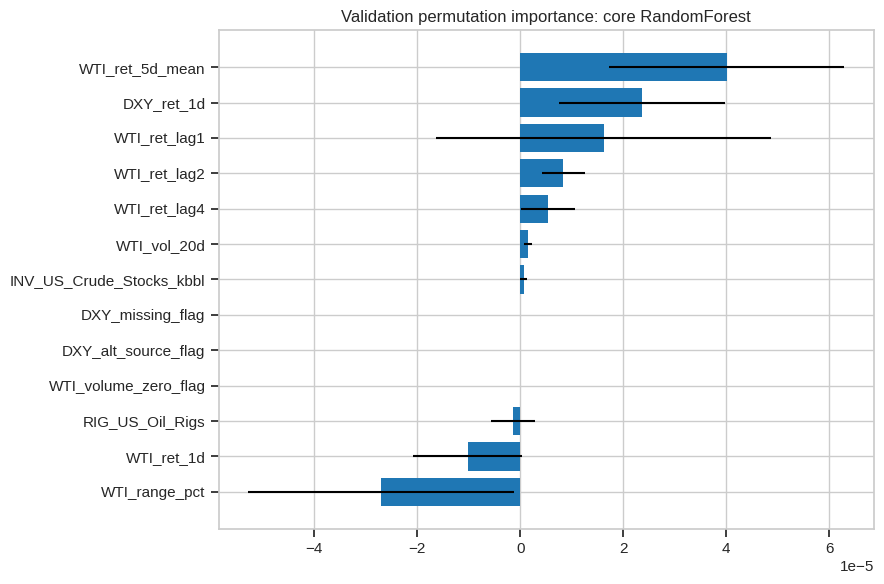

,feature,importance_mean,importance_std,set,model
1,WTI_ret_lag1,4.322401e-05,2.741287e-05,extended,RandomForest
6,WTI_range_pct,3.758980e-05,3.730067e-05,extended,RandomForest
5,WTI_vol_20d,2.659083e-05,2.701534e-05,extended,RandomForest
2,WTI_ret_lag2,2.287586e-05,1.550403e-05,extended,RandomForest
8,DXY_ret_1d,1.971951e-05,1.925588e-05,extended,RandomForest
4,WTI_ret_5d_mean,1.587042e-05,1.962180e-05,extended,RandomForest
21,GPR_threats_lag1m,1.185980e-05,8.325392e-06,extended,RandomForest
3,WTI_ret_lag4,1.065146e-05,6.605363e-06,extended,RandomForest
20,GPR_total_lag1m,5.949391e-06,5.547949e-06,extended,RandomForest
14,CMD_urals_lag1,5.167264e-06,3.728521e-06,extended,RandomForest


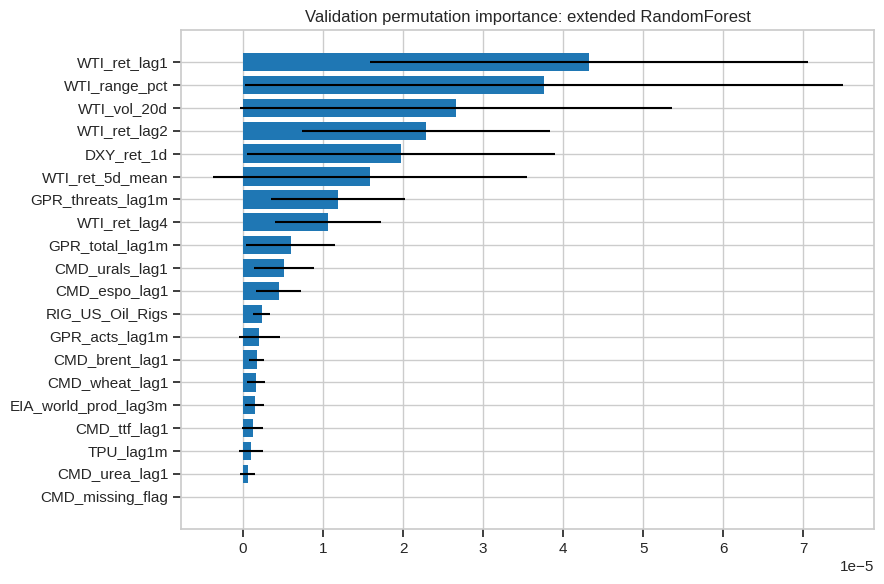

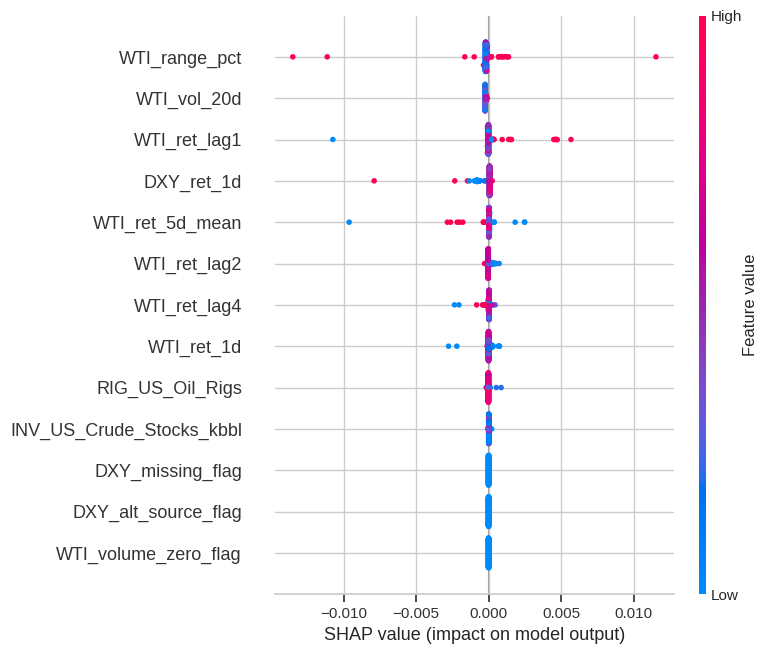

In [22]:
# Permutation importance on validation only (preferred for interpretation without reusing test).
importance_rows=[]
for set_name, train, val, features, models in [("core",core_train,core_val,CORE_FEATURES,core_models),
                                               ("extended",ext_train,ext_val,EXTENDED_FEATURES,ext_models)]:
    tree_names=[n for n in models if n in ["RandomForest","HistGradientBoosting","XGBoost","LightGBM"]]
    if not tree_names or len(val)==0: continue
    # Choose best tree by validation MAE, recorded during tuning.
    tuning = core_reg_val if set_name=="core" else ext_reg_val
    best_name=min(tree_names,key=lambda n:tuning[n]["val_mae"])
    result=permutation_importance(models[best_name],val[features],val[TARGET_RET],scoring="neg_mean_absolute_error",
                                  n_repeats=20,random_state=SEED,n_jobs=-1)
    imp=pd.DataFrame({"feature":features,"importance_mean":result.importances_mean,"importance_std":result.importances_std})
    imp["set"]=set_name; imp["model"]=best_name; importance_rows.append(imp)
    display(imp.sort_values("importance_mean",ascending=False).head(20))
    fig,ax=plt.subplots(figsize=(9,6)); topimp=imp.sort_values("importance_mean").tail(20)
    ax.barh(topimp.feature,topimp.importance_mean,xerr=topimp.importance_std); ax.set_title(f"Validation permutation importance: {set_name} {best_name}")
    fig.tight_layout(); fig.savefig(OUT/f"permutation_importance_{set_name}.png",dpi=150); plt.show()
if importance_rows: pd.concat(importance_rows).to_csv(OUT/"permutation_importance.csv",index=False)
# SHAP on best available fitted tree model; use validation subset only to keep runtime bounded.
try:
    import shap
    shap.initjs()
    candidates=[(n,m,CORE_FEATURES,"core") for n,m in core_models.items() if n in ["RandomForest","HistGradientBoosting","XGBoost","LightGBM"]]
    candidates += [(n,m,EXTENDED_FEATURES,"extended") for n,m in ext_models.items() if n in ["RandomForest","HistGradientBoosting","XGBoost","LightGBM"]]
    if candidates:
        # Tree models generally support TreeExplainer; use a bounded validation sample.
        name,model,features,set_name=candidates[0]
        sample=core_val if set_name=="core" else ext_val
        sample=sample[features].iloc[:min(300,len(sample))]
        try:
            explainer=shap.TreeExplainer(model); sv=explainer.shap_values(sample)
            shap.summary_plot(sv,sample,show=False,max_display=20)
            plt.tight_layout(); plt.savefig(OUT/f"shap_summary_{set_name}_{name}.png",dpi=150,bbox_inches="tight"); plt.show()
        except Exception as e: print("SHAP explanation unsupported for selected model/version:",repr(e))
    else: print("No tree model fitted for SHAP.")
except Exception as e:
    print("SHAP could not run in this environment:",repr(e))

**Conclusion:** Permutation importance is measured on validation data and can be unstable with correlated predictors. SHAP output is model- and sample-dependent, not causal evidence. The code catches SHAP version/model incompatibilities rather than silently asserting it succeeded.

## 23. Error by year and core-versus-extended comparison

,set,model,year,n,MAE,RMSE
0,core,Ridge,2024,252,0.014579,0.018502
1,core,Ridge,2025,250,0.015008,0.020254
2,core,Ridge,2026,192,0.028343,0.039155
3,core,Lasso,2024,252,0.014419,0.018294
4,core,Lasso,2025,250,0.014822,0.019991
5,core,Lasso,2026,192,0.028460,0.039255
6,core,ElasticNet,2024,252,0.014437,0.018324
7,core,ElasticNet,2025,250,0.014834,0.020013
8,core,ElasticNet,2026,192,0.028453,0.039280
9,core,RandomForest,2024,252,0.014368,0.018150


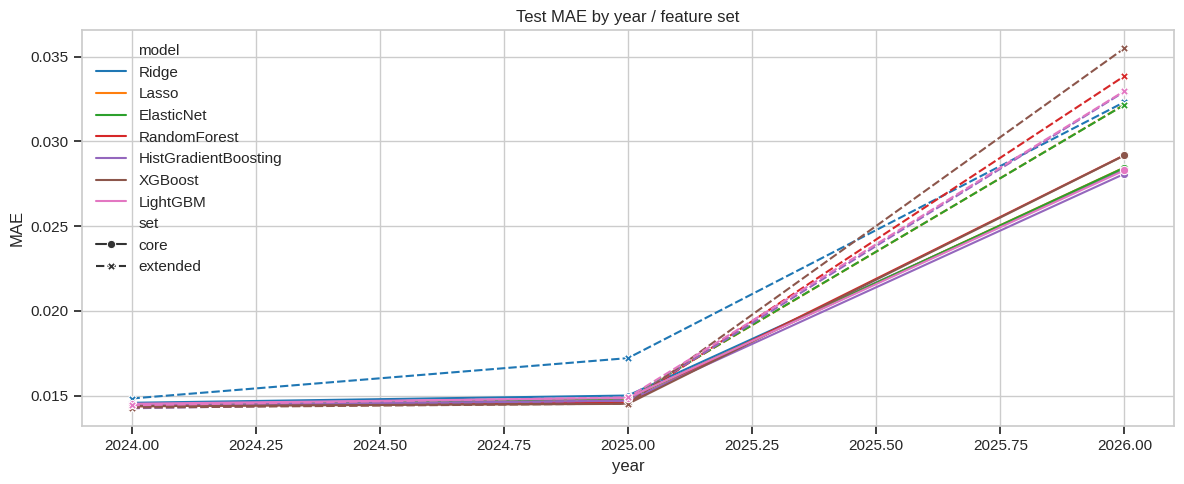

,model,n_test,return_MAE,return_RMSE,price_MAE,price_RMSE,MAE_improvement_vs_persistence_pct
11,extended_Lasso,585,0.017105,0.024952,1.269808,2.057616,32.526745
14,extended_HistGradientBoosting,585,0.017108,0.024789,1.271787,2.037669,32.514110
12,extended_ElasticNet,585,0.017119,0.024978,1.270592,2.059497,32.470016
17,extended_ZeroReturn,585,0.017126,0.024775,1.273043,2.035680,32.443039
13,extended_RandomForest,585,0.017209,0.024866,1.281671,2.045885,32.116170
16,extended_LightGBM,585,0.017263,0.024984,1.283525,2.057319,31.904131
15,extended_XGBoost,585,0.017405,0.025685,1.300653,2.139214,31.343693
4,core_HistGradientBoosting,694,0.018304,0.025946,1.413407,2.183609,31.241774
10,extended_Ridge,585,0.018332,0.026078,1.347272,2.110017,27.686366
7,core_ZeroReturn,694,0.018398,0.026046,1.421700,2.183718,30.887220


In [23]:
def yearly_errors(data, features, models, set_name):
    rows=[]
    for name,m in models.items():
        pred=m.predict(data[features])
        tmp=pd.DataFrame({"Date":data.Date.to_numpy(),"actual":data[TARGET_RET].to_numpy(),"pred":pred})
        tmp["year"]=tmp.Date.dt.year
        for year,g in tmp.groupby("year"):
            rows.append({"set":set_name,"model":name,"year":year,"n":len(g),"MAE":mean_absolute_error(g.actual,g.pred),"RMSE":rmse(g.actual,g.pred)})
    return pd.DataFrame(rows)
year_errors=pd.concat([yearly_errors(core_test,CORE_FEATURES,core_models,"core"),
                       yearly_errors(ext_test,EXTENDED_FEATURES,ext_models,"extended")],ignore_index=True) if len(ext_test) else yearly_errors(core_test,CORE_FEATURES,core_models,"core")
display(year_errors); year_errors.to_csv(OUT/"error_by_year.csv",index=False)
if len(year_errors):
    fig,ax=plt.subplots(figsize=(12,5)); sns.lineplot(data=year_errors,x="year",y="MAE",hue="model",style="set",markers=True,ax=ax)
    ax.set_title("Test MAE by year / feature set"); fig.tight_layout(); fig.savefig(OUT/"error_by_year.png",dpi=150); plt.show()
comparison=pd.concat([reg_results.assign(task="regression"),pd.DataFrame()],ignore_index=True)
display(reg_results.sort_values("return_MAE")[["model","n_test","return_MAE","return_RMSE","price_MAE","price_RMSE","MAE_improvement_vs_persistence_pct"]])

**Conclusion:** A model can look good in aggregate while failing in a specific regime. Core and extended comparisons also use different eligible rows; interpret differences with sample coverage in mind.

## 24. Optional small GRU (only if time/resources allow)

In [24]:
# Optional: set RUN_GRU=True to run a small sequence model. Uses chronological windows and train-only scaling.
RUN_GRU = False
if RUN_GRU:
    try:
        import torch
        from torch import nn
        torch.manual_seed(SEED)
        def run_gru(train,val,test,features,window=20,epochs=25):
            # No imputation: use only fully observed rows; windows must be contiguous in this eligible sequence.
            all_data=pd.concat([train,val,test]).sort_values("Date").reset_index(drop=True)
            split_train_end=len(train); split_val_end=len(train)+len(val)
            scaler=StandardScaler().fit(train[features])
            X=scaler.transform(all_data[features]); y=all_data[TARGET_RET].to_numpy()
            Xw=[]; yw=[]; target_indices=[]
            for i in range(window,len(all_data)):
                Xw.append(X[i-window:i]); yw.append(y[i]); target_indices.append(i)
            Xw=np.asarray(Xw,dtype=np.float32); yw=np.asarray(yw,dtype=np.float32); target_indices=np.asarray(target_indices)
            trmask=target_indices<split_train_end
            vamask=(target_indices>=split_train_end)&(target_indices<split_val_end)
            temask=target_indices>=split_val_end
            class GRUReg(nn.Module):
                def __init__(self,nfeat):
                    super().__init__(); self.gru=nn.GRU(nfeat,16,batch_first=True); self.fc=nn.Linear(16,1)
                def forward(self,x): return self.fc(self.gru(x)[0][:,-1,:]).squeeze(-1)
            model=GRUReg(len(features)); opt=torch.optim.Adam(model.parameters(),lr=.001); lossfn=nn.MSELoss()
            Xt=torch.tensor(Xw[trmask]); yt=torch.tensor(yw[trmask])
            for ep in range(epochs):
                model.train(); opt.zero_grad(); loss=lossfn(model(Xt),yt); loss.backward(); opt.step()
            model.eval()
            with torch.no_grad(): pred=model(torch.tensor(Xw[temask])).numpy()
            return pred, all_data.iloc[target_indices[temask]].copy()
        gru_pred,gru_test=run_gru(core_train,core_val,core_test,CORE_FEATURES)
        print("GRU test:",regression_metrics(gru_test,gru_pred,"core_GRU"))
    except Exception as e:
        print("Optional GRU failed:",repr(e),"- tree/linear models remain the primary comparison.")

**Conclusion:** The GRU is disabled by default to keep runtime predictable. If enabled, scaling is fitted on training data only; sequence-boundary and eligible-row continuity should be reviewed before treating it as a robust sequence experiment.

## 25. Final results table, limitations, and export

In [25]:
# Unified results table with all available metrics; task-specific columns are NaN where inapplicable.
final_table=pd.concat([
    reg_results.assign(task="regression"),
    pd.concat([core_dir_results,ext_dir_results],ignore_index=True).assign(task="direction")
],ignore_index=True,sort=False)
display(final_table)
final_table.to_csv(OUT/"all_model_metrics.csv",index=False)
summary = {
 "dataset_rows":int(len(df)), "date_start":str(df.Date.min().date()),"date_end":str(df.Date.max().date()),
 "core_eligible_rows":int((df.ELIGIBLE_core==1).sum()),"extended_eligible_rows":int((df.ELIGIBLE_extended==1).sum()),
 "test_start":"2024-01-01",
 "commodity_missing_rows_after_2026_04_30":int(((df.Date>="2026-05-01") & df[[c for c in df if c.startswith("CMD_") and c.endswith("_lag1")]].isna().all(axis=1)).sum()),
 "random_seed":SEED,
 "caveats":["No NaN imputation","No random split","weekly release timing unverified","monthly publication lags assumed",
            "commodity block missing/suspect after 2026-04-30","DXY alternate-source flag before 2016-10-07",
            "continuous WTI contract/roll definition should be documented","test performance is historical, not guaranteed"]
}
(OUT/"run_summary.json").write_text(json.dumps(summary,indent=2))
zip_path="/content/WTI_forecasting_outputs.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file(): zf.write(p,arcname=f"outputs/{p.relative_to(OUT)}")
print("Saved outputs:",len(list(OUT.rglob("*"))),"items")
print("ZIP:",zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download the ZIP from:",zip_path)

,model,n_test,return_MAE,return_RMSE,price_MAE,price_RMSE,price_persistence_MAE,return_zero_MAE,return_persistence_MAE,MAE_improvement_vs_persistence_pct,...,TN,FP,FN,TP,accuracy_diff_vs_MajorityClass,bootstrap95_low_vs_MajorityClass,bootstrap95_high_vs_MajorityClass,accuracy_diff_vs_PreviousReturnSign,bootstrap95_low_vs_PreviousReturnSign,bootstrap95_high_vs_PreviousReturnSign
0,core_Ridge,694.0,0.018541,0.026386,1.431460,2.217076,1.421700,0.018398,0.026621,30.349467,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,core_Lasso,694.0,0.018449,0.026302,1.425636,2.213469,1.421700,0.018398,0.026621,30.698273,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,core_ElasticNet,694.0,0.018457,0.026326,1.426275,2.215747,1.421700,0.018398,0.026621,30.665191,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,core_RandomForest,694.0,0.018553,0.026754,1.436795,2.260085,1.421700,0.018398,0.026621,30.307329,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,core_HistGradientBoosting,694.0,0.018304,0.025946,1.413407,2.183609,1.421700,0.018398,0.026621,31.241774,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,core_XGBoost,694.0,0.018523,0.026492,1.436321,2.243643,1.421700,0.018398,0.026621,30.420345,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,core_LightGBM,694.0,0.018456,0.026126,1.426055,2.196513,1.421700,0.018398,0.026621,30.669724,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,core_ZeroReturn,694.0,0.018398,0.026046,1.421700,2.183718,1.421700,0.018398,0.026621,30.887220,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,core_PreviousDayReturn,694.0,0.026621,0.036633,2.054398,3.055597,1.421700,0.018398,0.026621,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,core_SeasonalNaive5dMean,694.0,0.020533,0.028324,1.586958,2.377806,1.421700,0.018398,0.026621,22.869674,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saved outputs: 34 items
ZIP: /content/WTI_forecasting_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 26. Honest conclusion checklist
Before interpreting the output, record the actual measured results from `all_model_metrics.csv`. Do not declare a winner unless it improves on zero-return and persistence on the same test dates, and inspect uncertainty intervals / paired loss tests.

**Limitations to carry into any report**
- Commodity features are missing/suspect after 2026-04-30; Brent/Urals/ESPO alignment requires source-level verification.
- DXY uses an alternate source before 2016-10-07; the source transition can create measurement differences.
- Monthly GPR/TPU/EIA lags are assumed, not independently verified against release timestamps.
- Weekly rig-count and inventory release timing is unverified; observation week is not necessarily public-availability date.
- Continuous WTI contract definition, roll rule, and zero-volume rows need documentation.
- Regime shift risk is substantial; 2020 negative prices are real and make percentage returns / price reconstruction fragile around zero.
- Hyperparameter tuning and multiple model comparisons can overfit even with chronological splits.
- Suggested next steps: obtain raw source files and publication timestamps; test alternative contract/roll rules; model conditional volatility (e.g., GARCH); evaluate quantile forecasts and prediction intervals; consider a genuinely untouched later holdout as new data arrives.

## 27. Final deployment refit: train through the latest available labeled data

Run the following code cell after the earlier model-selection cells. It selects the core model using the existing validation results, then refits it on all eligible labeled rows before the latest forecast date. This is for producing a current forecast, not for unbiased performance evaluation.


In [26]:
# FINAL DEPLOYMENT MODEL: retrain on all currently available eligible historical labels
# Run this AFTER the notebook's model-selection/evaluation cells have completed.

# Use the core feature set because it has broader recent data coverage.
forecast_data = df.sort_values("Date").copy()
forecast_data["Date"] = pd.to_datetime(forecast_data["Date"])

# Forecast from the latest date with all core inputs available.
latest_candidates = forecast_data[forecast_data[CORE_FEATURES].notna().all(axis=1)].copy()
if latest_candidates.empty:
    raise ValueError("No rows have all CORE_FEATURES available.")
latest_row = latest_candidates.iloc[[-1]].copy()
forecast_date = latest_row["Date"].iloc[0]

# Train only on rows whose next-day return label is already known, strictly before forecast date.
train_all = forecast_data[
    (forecast_data["Date"] < forecast_date)
    & (forecast_data["ELIGIBLE_core"] == 1)
    & forecast_data[TARGET_RET].notna()
    & forecast_data[CORE_FEATURES].notna().all(axis=1)
].copy().sort_values("Date")

if len(train_all) < 100:
    raise ValueError(f"Too few eligible training rows: {len(train_all)}")

# Choose the model family/hyperparameters selected earlier using the validation period.
if "core_reg_val" in globals() and core_reg_val:
    chosen_name = min(core_reg_val, key=lambda k: core_reg_val[k]["val_mae"])
    final_model = clone(core_reg_val[chosen_name]["estimator"])
    print("Selected using validation MAE:", chosen_name)
else:
    # Safe fallback if the tuning cell was not run.
    chosen_name = "Ridge"
    final_model = Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=1.0))])
    print("Tuning results unavailable; using fallback Ridge model.")

final_model.fit(train_all[CORE_FEATURES], train_all[TARGET_RET])
pred_return = float(final_model.predict(latest_row[CORE_FEATURES])[0])
current_close = float(latest_row["WTI_Close"].iloc[0])
pred_price = current_close * (1 + pred_return)

print("\n--- UPDATED FULL-HISTORY FORECAST ---")
print("Latest feature date:", forecast_date.date())
print("Training rows:", len(train_all))
print("Training label dates:", train_all["Date"].min().date(), "to", train_all["Date"].max().date())
print("Model:", chosen_name)
print("Current WTI close:", round(current_close, 4))
print("Predicted next-day return (%):", round(pred_return * 100, 4))
print("Predicted next-day WTI price:", round(pred_price, 4))
print("NOTE: Experimental forecast, not a guarantee. This refit uses all eligible labeled data available before the forecast date.")


Selected using validation MAE: Lasso

--- UPDATED FULL-HISTORY FORECAST ---
Latest feature date: 2026-10-07
Training rows: 2979
Training label dates: 2014-11-17 to 2026-10-06
Model: Lasso
Current WTI close: 88.28
Predicted next-day return (%): 0.0782
Predicted next-day WTI price: 88.349
NOTE: Experimental forecast, not a guarantee. This refit uses all eligible labeled data available before the forecast date.
